<a href="https://colab.research.google.com/github/Sean-TEE/akmola-cropland-degradation/blob/main/WorldCereal_GEE.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install geemap -q

In [ ]:
import ee
ee.Authenticate()
ee.Initialize(project='akmola')

In [ ]:
gaul = ee.FeatureCollection("FAO/GAUL/2015/level1")
kz = gaul.filter(ee.Filter.eq('ADM0_NAME', 'Kazakhstan'))
print(kz.aggregate_array('ADM1_NAME').getInfo())

['Akmolinskaya', 'Aktyubinskaya', 'Almatinskaya', 'Atyrauskaya', 'Jambylslkaya', 'Karagandinskaya', 'Kustanayskaya', 'Kyzylordinskaya', 'Administrative unit not available', 'Mangistauskaya', 'Pavlodarskaya', 'Severo-kazachstanskaya', 'Vostochno-kazachstanskaya', 'Yujno-kazachstanskaya', 'Zapadno-kazachstanskaya', 'Almaty City area']


In [ ]:
AKMOLA_NAME = 'Akmolinskaya'
aoi = kz.filter(ee.Filter.eq('ADM1_NAME', AKMOLA_NAME)).geometry()

In [ ]:
# WorldCover 2021 v200: класс 40 = cropland
wc = ee.ImageCollection('ESA/WorldCover/v200').first().select('Map')
wc_crop = wc.eq(40)

# WorldCereal 2021: годовая маска temporary crops (100 = пашня)
wcer_col = (ee.ImageCollection('ESA/WorldCereal/2021/MODELS/v100')
            .filter(ee.Filter.eq('product', 'temporarycrops')))
wcer_crop = wcer_col.mosaic().select('classification').eq(100)

# Карта согласия:
# 0 = ни один, 1 = только WorldCereal, 2 = только WorldCover, 3 = оба
agreement = wc_crop.multiply(2).add(wcer_crop).clip(aoi).rename('agreement')

In [ ]:
areas = ee.Image.pixelArea().divide(1e6).addBands(agreement).reduceRegion(
    reducer=ee.Reducer.sum().group(groupField=1, groupName='class'),
    geometry=aoi, scale=100, maxPixels=1e13, tileScale=4
).getInfo()

labels = {0: 'ни один', 1: 'только WorldCereal', 2: 'только WorldCover', 3: 'оба продукта'}
total = sum(g['sum'] for g in areas['groups'])
for g in areas['groups']:
    print(f"{labels[g['class']]}: {g['sum']:,.0f} км² ({100*g['sum']/total:.1f}%)")

ни один: 65,621 км² (53.9%)
только WorldCereal: 426 км² (0.4%)
только WorldCover: 16,481 км² (13.5%)
оба продукта: 39,209 км² (32.2%)


In [ ]:
import geemap
Map = geemap.Map()
Map.centerObject(aoi, 7)
pal = ['dddddd', '2166ac', 'b2182b', '1a9850']  # серый/синий/красный/зелёный
Map.addLayer(agreement, {'min': 0, 'max': 3, 'palette': pal}, 'WC vs WorldCereal')
Map.addLayer(ee.Image().paint(aoi, 0, 2), {'palette': 'black'}, 'Граница AOI')
Map

Map(center=[51.55168116741634, 69.77636868779749], controls=(WidgetControl(options=['position', 'transparent_b…

In [ ]:
import pandas as pd

sample = agreement.stratifiedSample(
    numPoints=0, classBand='agreement',
    classValues=[1, 2], classPoints=[50, 50],
    region=aoi, scale=10, seed=42, geometries=True
)

feats = sample.getInfo()['features']
rows = [{'lon': f['geometry']['coordinates'][0],
         'lat': f['geometry']['coordinates'][1],
         'who_says_crop': {1: 'WorldCereal', 2: 'WorldCover'}[f['properties']['agreement']]}
        for f in feats]
df = pd.DataFrame(rows)
df.to_csv('disagreement_points.csv', index=False)
print(df.head(10))

         lon        lat who_says_crop
0  66.056866  51.261843   WorldCereal
1  68.053551  51.092151   WorldCereal
2  70.086259  51.436475   WorldCereal
3  70.145278  51.445548   WorldCereal
4  70.578805  51.280707   WorldCereal
5  70.126414  51.290319   WorldCereal
6  68.739684  50.986240   WorldCereal
7  67.093162  50.502317   WorldCereal
8  70.555808  51.702646   WorldCereal
9  69.591826  50.400179   WorldCereal


In [ ]:
import pandas as pd

wc_only = agreement.eq(2)  # только WorldCover

# крупные связные массивы: >= 50 связных пикселей (~5 га при 10 м)
patch_size = wc_only.connectedPixelCount(maxSize=200, eightConnected=True)
big_patches = wc_only.And(patch_size.gte(50))

# Выборка A: крупные связные пятна (вероятные залежи)
sample_patches = big_patches.selfMask().stratifiedSample(
    numPoints=40, region=aoi, scale=10, seed=1, geometries=True)

# Выборка B: весь класс "только WorldCover" случайно (для общей оценки)
sample_random = wc_only.selfMask().stratifiedSample(
    numPoints=40, region=aoi, scale=10, seed=2, geometries=True)

def to_rows(fc, tag):
    return [{'lon': f['geometry']['coordinates'][0],
             'lat': f['geometry']['coordinates'][1],
             'group': tag} for f in fc.getInfo()['features']]

df = pd.DataFrame(to_rows(sample_patches, 'patch') + to_rows(sample_random, 'random'))
df['label'] = ''  # сюда впишешь: cropland / fallow / steppe / other
df.to_csv('validation_points.csv', index=False)
print(df['group'].value_counts())
print(df.head())

group
patch     40
random    40
Name: count, dtype: int64
         lon        lat  group label
0  69.124253  50.752678  patch      
1  72.146186  51.988131  patch      
2  72.772940  51.466838  patch      
3  70.895551  50.788970  patch      
4  68.241838  51.498549  patch      


In [ ]:
s2 = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
      .filterBounds(aoi).filterDate('2021-06-01', '2021-08-31')
      .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 20)).median())
Map.addLayer(s2, {'bands': ['B4','B3','B2'], 'min':0, 'max':3000}, 'S2 true color')

In [ ]:
Map

Map(center=[51.55168116741634, 69.77636868779749], controls=(WidgetControl(options=['position', 'transparent_b…

In [ ]:
print(aoi.centroid(1).coordinates().getInfo())

[69.77636868779749, 51.55168116741634]


In [ ]:
def mask_s2(img):
    scl = img.select('SCL')
    good = scl.neq(3).And(scl.neq(8)).And(scl.neq(9)).And(scl.neq(10))
    return img.updateMask(good)

s2 = (ee.ImageCollection('COPERNICUS/S2_SR_HARMONIZED')
      .filterBounds(aoi).filterDate('2021-06-15', '2021-07-31')
      .filter(ee.Filter.lt('CLOUDY_PIXEL_PERCENTAGE', 40))
      .map(mask_s2).median().clip(aoi))

Map = geemap.Map()
Map.centerObject(aoi, 7)
Map.addLayer(s2, {'bands': ['B4','B3','B2'], 'min': 0, 'max': 3000}, 'S2 true color')
Map.addLayer(agreement.selfMask(),
             {'min': 1, 'max': 3, 'palette': ['2166ac','b2182b','1a9850']},
             'WC vs WorldCereal')
Map

Map(center=[51.55168116741634, 69.77636868779749], controls=(WidgetControl(options=['position', 'transparent_b…

In [ ]:
pts_fc = ee.FeatureCollection([
    ee.Feature(ee.Geometry.Point([r.lon, r.lat]), {'group': r.group})
    for r in df.itertuples()
])
Map.addLayer(pts_fc.filter(ee.Filter.eq('group', 'patch')),
             {'color': 'yellow'}, 'patch-точки')
Map

Map(center=[51.55168116741634, 69.77636868779749], controls=(WidgetControl(options=['position', 'transparent_b…

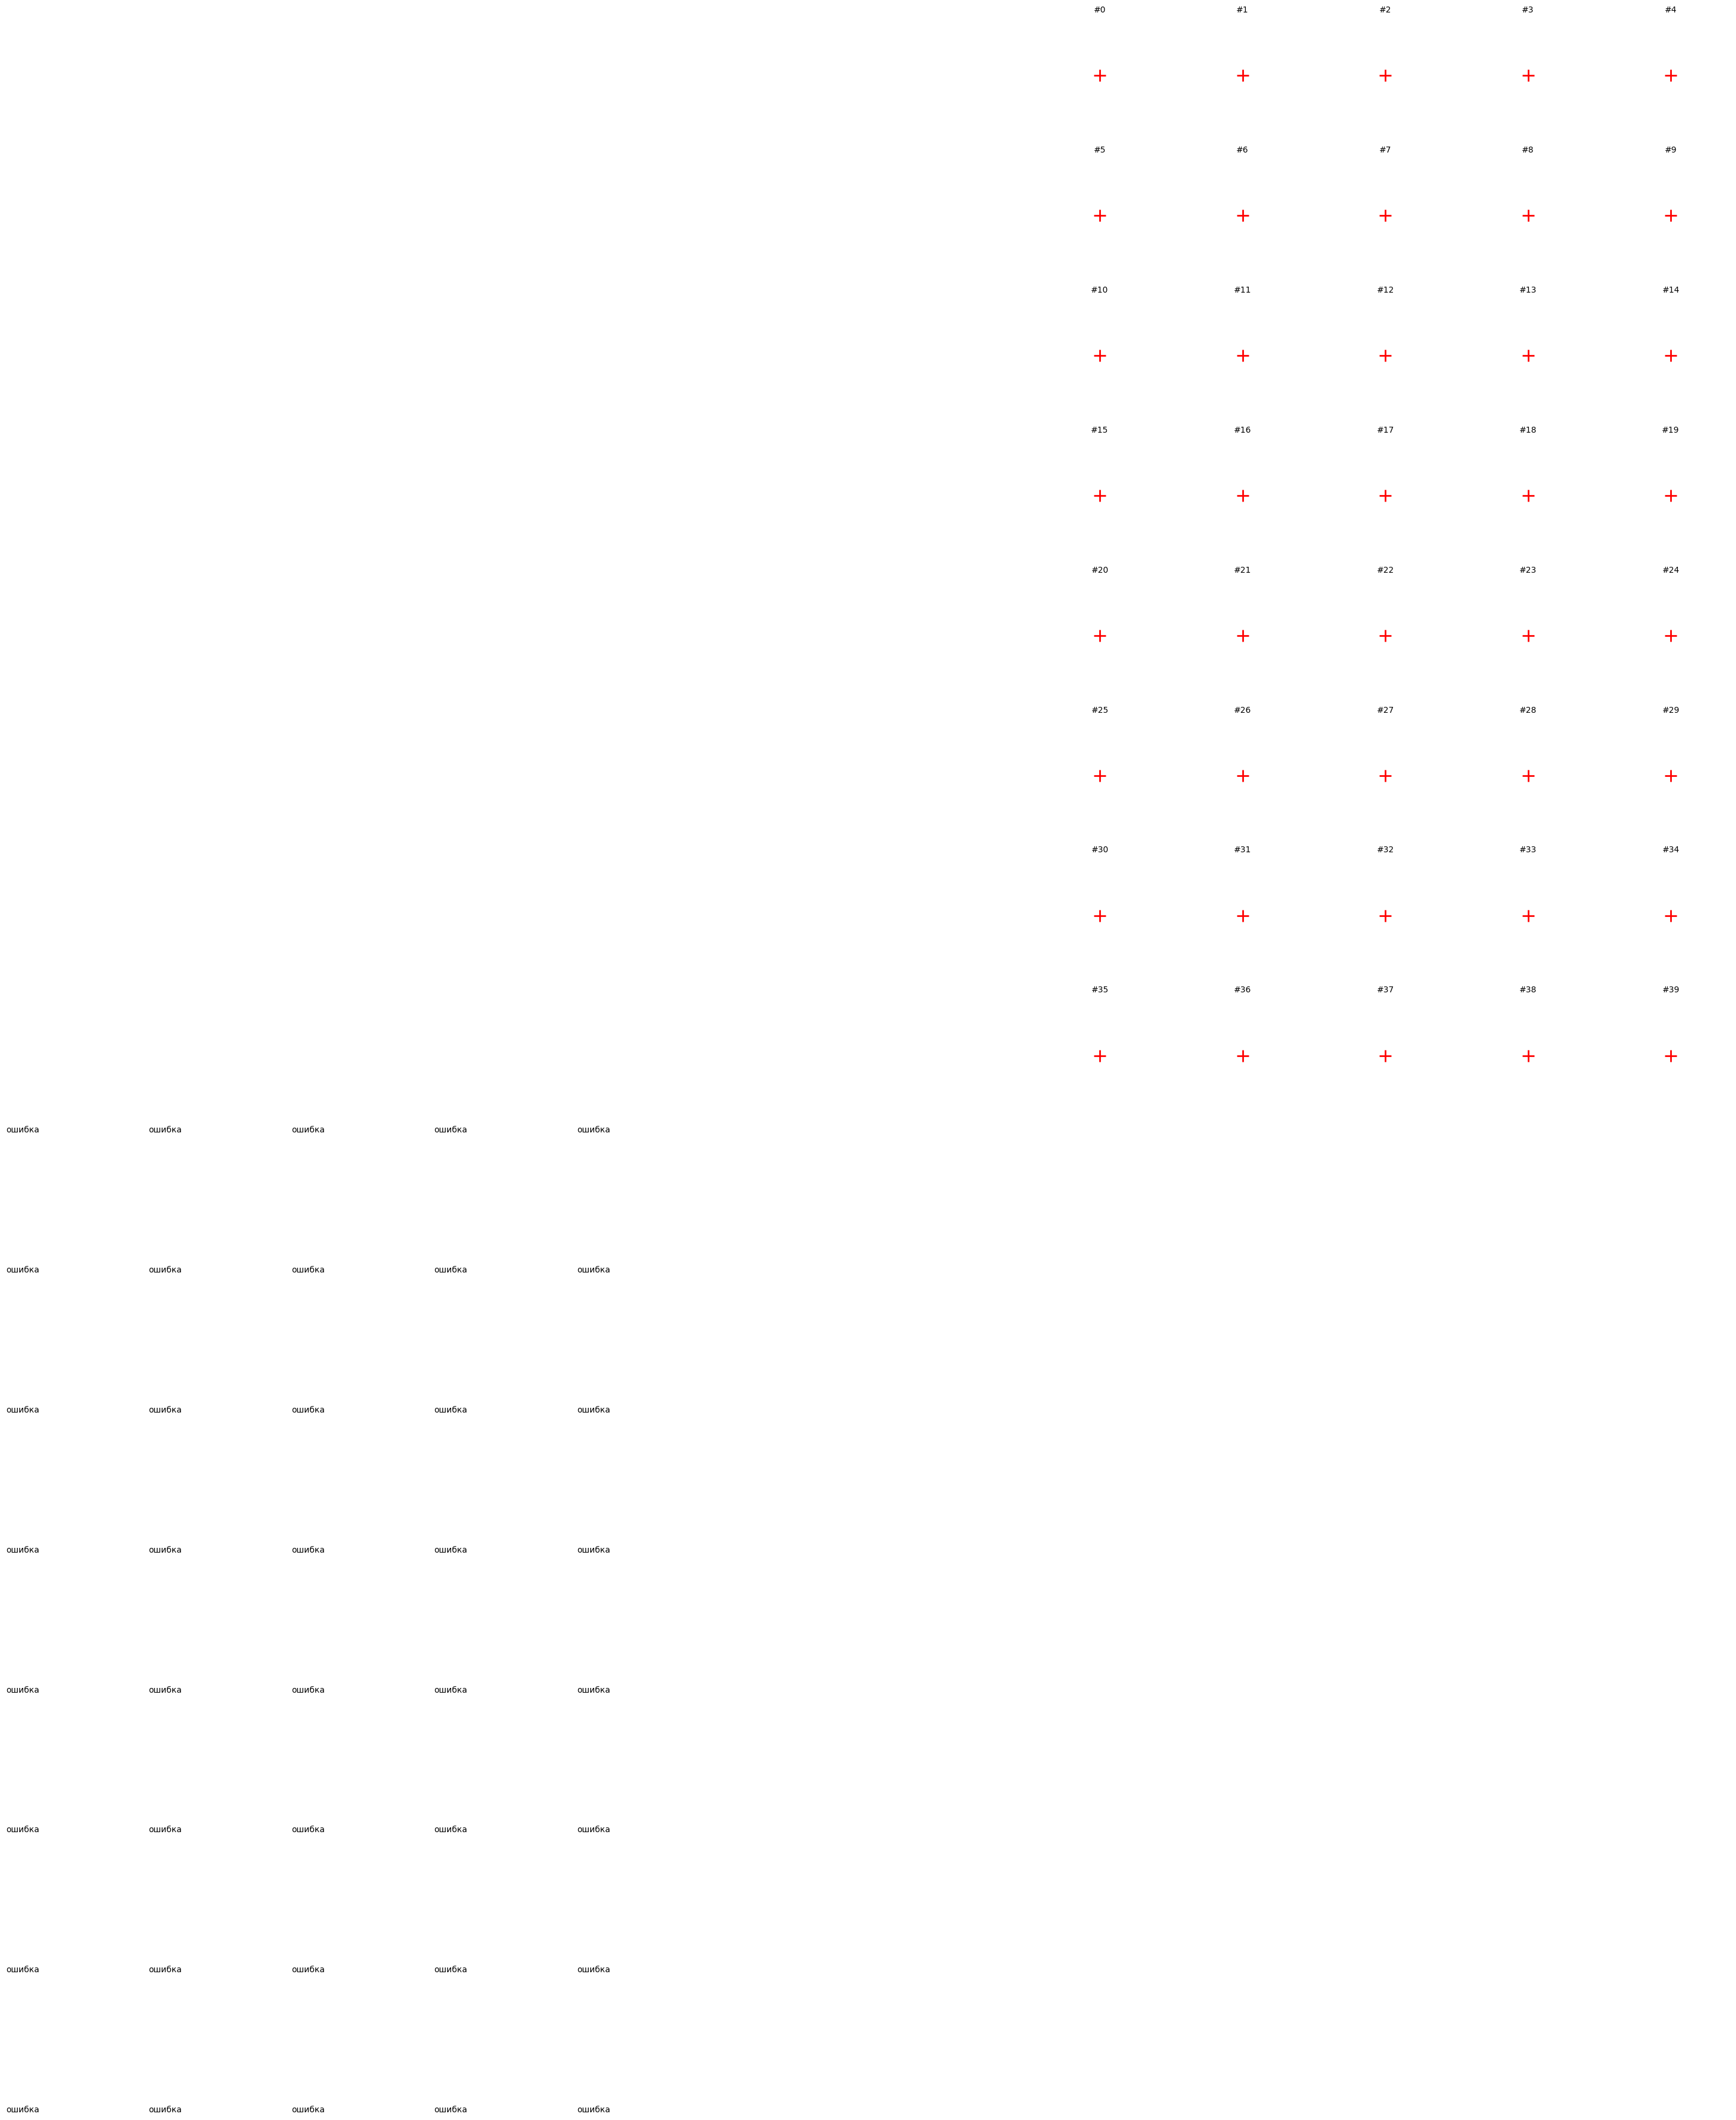


Всего точек: 40
Метки: cropland / fallow / steppe / other
Критерии: прямая нарезка=cropland | контур+мозаика зарастания=fallow |
          рельефная органика без кромок=steppe | пойма/вода/застройка=other


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from urllib.request import urlopen
import math

# те же параметры S2, что на карте
vis = {'bands': ['B4','B3','B2'], 'min': 0, 'max': 3000}
HALF = 0.02  # ~2 км половина стороны выреза (в градусах, грубо)

def thumb_url(lon, lat):
    region = ee.Geometry.Rectangle(
        [lon-HALF, lat-HALF, lon+HALF, lat+HALF])
    return s2.getThumbURL({**vis, 'region': region,
                           'dimensions': 256, 'format': 'png'})

# берём только patch-группу
patch_df = df[df['group'] == 'patch'].reset_index(drop=True)
n = len(patch_df)
cols = 5
rows = math.ceil(n / cols)

fig, axes = plt.subplots(rows, cols, figsize=(cols*3, rows*3))
axes = axes.flatten()

for i, r in patch_df.iterrows():
    try:
        img = mpimg.imread(urlopen(thumb_url(r.lon, r.lat)), format='png')
        axes[i].imshow(img)
    except Exception as e:
        axes[i].text(0.5, 0.5, 'ошибка', ha='center')
    # красный крестик в центр = сама точка
    axes[i].plot(128, 128, marker='+', color='red', markersize=14, markeredgewidth=2)
    axes[i].set_title(f"#{i}", fontsize=10)
    axes[i].axis('off')

for j in range(n, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.savefig('patch_grid.png', dpi=100, bbox_inches='tight')
plt.show()

print(f"\nВсего точек: {n}")
print("Метки: cropland / fallow / steppe / other")
print("Критерии: прямая нарезка=cropland | контур+мозаика зарастания=fallow |")
print("          рельефная органика без кромок=steppe | пойма/вода/застройка=other")

In [ ]:
url = thumb_url(patch_df.iloc[0].lon, patch_df.iloc[0].lat)
print(url)

https://earthengine.googleapis.com/v1/projects/akmola/thumbnails/1618695e86943fc1a284a8d513134297-e1c68a7d95a8c0c246b7ebfa1d0616c9:getPixels


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import os, math

os.makedirs('thumbs', exist_ok=True)
patch_df = df[df['group'] == 'patch'].reset_index(drop=True)
vis = {'bands': ['B4','B3','B2'], 'min': 0, 'max': 3000}
HALF = 0.02

for i, r in patch_df.iterrows():
    region = ee.Geometry.Rectangle([r.lon-HALF, r.lat-HALF, r.lon+HALF, r.lat+HALF])
    out = f'thumbs/pt_{i:02d}.png'
    if not os.path.exists(out):
        geemap.get_image_thumbnail(s2, out, vis_params=vis,
                                   dimensions=256, region=region, format='png')
    print(f'{i} готов')

0 готов
1 готов
2 готов
3 готов
4 готов
5 готов
6 готов
7 готов
8 готов
9 готов
10 готов
11 готов
12 готов
13 готов
14 готов
15 готов
16 готов
17 готов
18 готов
19 готов
20 готов
21 готов
22 готов
23 готов
24 готов
25 готов
26 готов
27 готов
28 готов
29 готов
30 готов
31 готов
32 готов
33 готов
34 готов
35 готов
36 готов
37 готов
38 готов
39 готов


In [ ]:
# n = len(patch_df); cols = 5; rows = math.ceil(n/cols)
# fig, axes = plt.subplots(rows, cols, figsize=(cols*3, rows*3))
# axes = axes.flatten()
# for i in range(n):
#     p = f'thumbs/pt_{i:02d}.png'
#     if os.path.exists(p):
#         axes[i].imshow(mpimg.imread(p))
#     axes[i].plot(128, 128, marker='+', color='red', markersize=14, markeredgewidth=2)
#     axes[i].set_title(f'#{i}', fontsize=10)
#     axes[i].axis('off')
# for j in range(n, len(axes)): axes[j].axis('off')
# plt.tight_layout(); plt.show()

In [ ]:
labels_dict = {
    0:  'steppe',    # рельеф, эрозионные пятна, светлый оголённый участок — не поле
    1:  'cropland',  # чёткая нарезка парцелл
    2:  'cropland',  # прямые кромки, поймa слева не под крестиком
    3:  'cropland',  # крупные прямоугольные поля
    4:  'fallow',    # контур есть, но дугообразные полосы/зарастание
    5:  'cropland',  # ровные поля, прямые границы
    6:  'steppe',    # бурый рельеф, нет геометрии — СПОРНО, проверь
    7:  'cropland',  # нарезка читается
    8:  'cropland',  # поля + водоём снизу (не под крестиком)
    9:  'fallow',    # слабая геометрия, сухой тон — СПОРНО
    10: 'cropland',  # поле, водоток слева не под точкой
    11: 'other',     # пойма/солончак, светлые пятна воды — СПОРНО
    12: 'steppe',    # выраженный рельеф, извилины, нет кромок
    13: 'cropland',  # прямые границы, водоём мелкий не под точкой
    14: 'other',     # река/пойма прямо в кадре
    15: 'cropland',  # поля, водоток сверху не под точкой
    16: 'cropland',  # нарезка парцелл
    17: 'cropland',  # прямые кромки, западинка не под точкой
    18: 'steppe',    # почти однородный сухой, эрозионные линии — СПОРНО
    19: 'fallow',    # мозаика зарастания в контуре — СПОРНО
    20: 'steppe',    # рельеф, диагональные размытые полосы
    21: 'cropland',  # поле, водоток вертикальный рядом не под точкой
    22: 'cropland',  # прямая граница поля через кадр
    23: 'cropland',  # чёткая нарезка + село снизу (не под точкой)
    24: 'fallow',    # геометрия слабая, сухо — СПОРНО
    25: 'steppe',    # размытый рельеф, дорога — СПОРНО
    26: 'cropland',  # поле, озеро снизу не под точкой
    27: 'steppe',    # сильный эрозионный рельеф, дуги
    28: 'cropland',  # прямоугольные поля
    29: 'cropland',  # нарезка, застройка справа не под точкой
    30: 'steppe',    # пятнистая природная текстура, кусты — СПОРНО
    31: 'cropland',  # ровные парцеллы
    32: 'cropland',  # поля, слабый водоток не под точкой
    33: 'cropland',  # прямые границы
    34: 'cropland',  # поле, водоток слева не под точкой
    35: 'other',     # выраженная извилистая пойма в кадре
    36: 'cropland',  # прямая нарезка, дорога
    37: 'cropland',  # поля, водоток снизу не под точкой
    38: 'other',     # водоём/пойма прямо под крестиком — СПОРНО
    39: 'steppe',    # рельеф, размытые границы — СПОРНО
}
patch_df['label'] = patch_df.index.map(labels_dict)
patch_df.to_csv('patch_labeled.csv', index=False)
print(patch_df['label'].value_counts())

label
cropland    23
steppe       9
fallow       4
other        4
Name: count, dtype: int64


In [ ]:
import pandas as pd
patch = pd.read_csv('patch_labeled.csv')

is_crop = patch['label'].isin(['cropland', 'fallow'])
n = len(patch)
print(f"Пашня (cropland+fallow): {is_crop.sum()}/{n} = {100*is_crop.mean():.0f}%")
print(f"Не пашня (steppe+other): {(~is_crop).sum()}/{n} = {100*(~is_crop).mean():.0f}%")
print(patch['label'].value_counts())

Пашня (cropland+fallow): 27/40 = 68%
Не пашня (steppe+other): 13/40 = 32%
label
cropland    23
steppe       9
fallow       4
other        4
Name: count, dtype: int64


In [ ]:
import os
os.makedirs('thumbs_random', exist_ok=True)
random_df = df[df['group'] == 'random'].reset_index(drop=True)
vis = {'bands': ['B4','B3','B2'], 'min': 0, 'max': 3000}
HALF = 0.02

for i, r in random_df.iterrows():
    region = ee.Geometry.Rectangle([r.lon-HALF, r.lat-HALF, r.lon+HALF, r.lat+HALF])
    out = f'thumbs_random/pt_{i:02d}.png'
    if not os.path.exists(out):
        geemap.get_image_thumbnail(s2, out, vis_params=vis,
                                   dimensions=256, region=region, format='png')
    print(f'{i} готов')

0 готов
1 готов
2 готов
3 готов
4 готов
5 готов
6 готов
7 готов
8 готов
9 готов
10 готов
11 готов
12 готов
13 готов
14 готов
15 готов
16 готов
17 готов
18 готов
19 готов
20 готов
21 готов
22 готов
23 готов
24 готов
25 готов
26 готов
27 готов
28 готов
29 готов
30 готов
31 готов
32 готов
33 готов
34 готов
35 готов
36 готов
37 готов
38 готов
39 готов


In [ ]:
# import matplotlib.pyplot as plt
# import matplotlib.image as mpimg
# import math

# n = len(random_df); cols = 5; rows = math.ceil(n/cols)
# fig, axes = plt.subplots(rows, cols, figsize=(cols*3, rows*3))
# axes = axes.flatten()
# for i in range(n):
#     p = f'thumbs_random/pt_{i:02d}.png'
#     if os.path.exists(p):
#         axes[i].imshow(mpimg.imread(p))
#     axes[i].plot(128, 128, marker='+', color='red', markersize=14, markeredgewidth=2)
#     axes[i].set_title(f'#{i}', fontsize=10)
#     axes[i].axis('off')
# for j in range(n, len(axes)): axes[j].axis('off')
# plt.tight_layout(); plt.show()

In [ ]:
labels_dict_random = {
    0:  'steppe',    # мягкий рельеф, нет прямых кромок, пятна
    1:  'cropland',  # дорога+поля, кромки читаются
    2:  'cropland',  # нарезка парцелл видна
    3:  'cropland',  # крупное ровное поле, слабые линии обработки
    4:  'cropland',  # поля + ферма/застройка сверху (не под точкой)
    5:  'cropland',  # прямые линии полей, дорога
    6:  'steppe',    # размытый склон, дуги, нет геометрии — СПОРНО
    7:  'cropland',  # поле, водоток справа не под точкой
    8:  'cropland',  # крупные прямоугольные поля
    9:  'steppe',    # пятнистый сухой рельеф, нет кромок — СПОРНО
    10: 'steppe',    # редкая пятнистость, пастбище — СПОРНО
    11: 'steppe',    # мозаика кустов/деревьев — залежь или пастбище, СПОРНО
    12: 'cropland',  # прямая диагональная кромка поля
    13: 'cropland',  # поля + полоса/лесополоса, застройка не под точкой
    14: 'steppe',    # пятна растительности, водотоки, нет нарезки
    15: 'steppe',    # почти однородный бурый, эрозионные линии — СПОРНО
    16: 'cropland',  # слабые кромки, дренажные линии — СПОРНО
    17: 'other',     # село + река прямо в кадре под точкой
    18: 'cropland',  # поля с полосами (лесополосы/орошение)
    19: 'other',     # выраженная извилистая пойма/старицы
    20: 'steppe',    # эрозионный рельеф, ветвящиеся ложбины
    21: 'cropland',  # слабая нарезка, сухо — СПОРНО
    22: 'cropland',  # кромки полей читаются
    23: 'steppe',    # пятнистая мозаика (солонцы/пастбище) — СПОРНО
    24: 'other',     # озеро/водоём в кадре, но точка рядом — СПОРНО
    25: 'cropland',  # прямые границы, дорога
    26: 'cropland',  # поля, диагональные линии
    27: 'cropland',  # поля + пойма слева (не под точкой)
    28: 'cropland',  # крупное ровное поле
    29: 'cropland',  # прямая кромка, водоём снизу не под точкой
    30: 'steppe',    # размытый рельеф, кусты — СПОРНО
    31: 'steppe',    # пятнистый, тёмное пятно, нет кромок — СПОРНО
    32: 'cropland',  # поля, водоток вертикальный не под точкой
    33: 'cropland',  # прямоугольные поля
    34: 'cropland',  # нарезка + водоток слева не под точкой
    35: 'other',     # пойма/вода, светлые пятна застройки
    36: 'steppe',    # размытый склон, водоток — СПОРНО
    37: 'cropland',  # ровные поля
    38: 'cropland',  # прямая кромка поля
    39: 'cropland',  # поля, водоём снизу не под точкой
}
random_df['label'] = random_df.index.map(labels_dict_random)
random_df.to_csv('random_labeled.csv', index=False)
print(random_df['label'].value_counts())

label
cropland    24
steppe      12
other        4
Name: count, dtype: int64


In [ ]:
import pandas as pd

patch = pd.read_csv('patch_labeled.csv')
rand = pd.read_csv('random_labeled.csv')

def summary(df, name):
    is_crop = df['label'].isin(['cropland', 'fallow'])
    print(f"\n=== {name} (n={len(df)}) ===")
    print(df['label'].value_counts().to_string())
    print(f"Пашня (crop+fallow): {is_crop.sum()}/{len(df)} = {100*is_crop.mean():.1f}%")
    print(f"Не пашня (steppe+other): {(~is_crop).sum()}/{len(df)} = {100*(~is_crop).mean():.1f}%")
    return is_crop.sum(), len(df)

pc, pn = summary(patch, 'PATCH (крупные пятна)')
rc, rn = summary(rand, 'RANDOM (весь спорный класс)')

# объединённая оценка
print(f"\n=== ОБЩАЯ (n={pn+rn}) ===")
print(f"WorldCover прав (реальная пашня): {pc+rc}/{pn+rn} = {100*(pc+rc)/(pn+rn):.1f}%")
print(f"WorldCover ошибся (степь/пойма): {(pn+rn)-(pc+rc)}/{pn+rn} = {100*((pn+rn)-(pc+rc))/(pn+rn):.1f}%")


=== PATCH (крупные пятна) (n=40) ===
label
cropland    23
steppe       9
fallow       4
other        4
Пашня (crop+fallow): 27/40 = 67.5%
Не пашня (steppe+other): 13/40 = 32.5%

=== RANDOM (весь спорный класс) (n=40) ===
label
cropland    24
steppe      12
other        4
Пашня (crop+fallow): 24/40 = 60.0%
Не пашня (steppe+other): 16/40 = 40.0%

=== ОБЩАЯ (n=80) ===
WorldCover прав (реальная пашня): 51/80 = 63.8%
WorldCover ошибся (степь/пойма): 29/80 = 36.2%


In [ ]:
# База: WorldCover cropland (класс 40) = зоны согласия + "только WorldCover"
cropland_mask = wc_crop.clip(aoi).rename('cropland')

# Флаг достоверности:
#   2 = высокая (оба продукта согласны)
#   1 = пониженная (только WorldCover; валидация ~64% пашни)
confidence = (agreement.eq(3).multiply(2)
              .add(agreement.eq(2).multiply(1))
              .rename('confidence'))

# Итоговый двухслойный продукт: маска + флаг
final_mask = cropland_mask.addBands(confidence).updateMask(cropland_mask)

# Площади по уровням достоверности
stats = ee.Image.pixelArea().divide(1e6).addBands(confidence).updateMask(cropland_mask).reduceRegion(
    reducer=ee.Reducer.sum().group(groupField=1, groupName='conf'),
    geometry=aoi, scale=100, maxPixels=1e13, tileScale=4).getInfo()

lab = {1: 'пониженная (только WC, ~64% пашни)', 2: 'высокая (оба согласны)'}
tot = sum(g['sum'] for g in stats['groups'])
print('=== Финальная cropland-маска, площади по достоверности ===')
for g in stats['groups']:
    print(f"{lab[g['conf']]}: {g['sum']:,.0f} км² ({100*g['sum']/tot:.1f}%)")
print(f"ИТОГО пашня: {tot:,.0f} км²")

=== Финальная cropland-маска, площади по достоверности ===
пониженная (только WC, ~64% пашни): 16,481 км² (29.6%)
высокая (оба согласны): 39,209 км² (70.4%)
ИТОГО пашня: 55,690 км²


In [ ]:
# task = ee.batch.Export.image.toAsset(
#     image=final_mask.toByte(),
#     description='akmola_cropland_mask_v1',
#     assetId='projects/akmola/assets/cropland_mask_v1',
#     region=aoi,
#     scale=10,
#     maxPixels=1e13
# )
# task.start()
# print('Экспорт запущен. Статус: https://code.earthengine.google.com/tasks')

In [ ]:
# task = ee.batch.Export.image.toDrive(
#     image=final_mask.toByte(),
#     description='akmola_cropland_mask_v1',
#     folder='akmola_masks', fileNamePrefix='cropland_mask_v1',
#     region=aoi, scale=10, maxPixels=1e13)
# task.start()

In [ ]:
mask = ee.Image('projects/akmola/assets/cropland_mask_v1')
print('Бэнды:', mask.bandNames().getInfo())  # ждём ['cropland', 'confidence']

# контроль площадей — должны совпасть с тем, что было до экспорта
check = ee.Image.pixelArea().divide(1e6).addBands(mask.select('confidence')).updateMask(
    mask.select('cropland')).reduceRegion(
    reducer=ee.Reducer.sum().group(groupField=1, groupName='conf'),
    geometry=aoi, scale=100, maxPixels=1e13, tileScale=4).getInfo()
for g in check['groups']:
    print(f"conf={g['conf']}: {g['sum']:,.0f} км²")

Бэнды: ['cropland', 'confidence']
conf=1: 23,378 км²
conf=2: 42,286 км²


In [ ]:
mask = ee.Image('projects/akmola/assets/cropland_mask_v1')
check10 = ee.Image.pixelArea().divide(1e6).addBands(mask.select('confidence')).updateMask(
    mask.select('cropland')).reduceRegion(
    reducer=ee.Reducer.sum().group(groupField=1, groupName='conf'),
    geometry=aoi, scale=10, maxPixels=1e13, tileScale=8).getInfo()
for g in check10['groups']:
    print(f"conf={g['conf']}: {g['sum']:,.0f} км²")

conf=1: 16,783 км²
conf=2: 39,163 км²


In [ ]:
mask = ee.Image('projects/akmola/assets/cropland_mask_v1')
crop = mask.select('cropland')

def mask_l8(img):
    qa = img.select('QA_PIXEL')
    # биты 3 (cloud) и 4 (cloud shadow) должны быть 0
    clear = qa.bitwiseAnd(1<<3).eq(0).And(qa.bitwiseAnd(1<<4).eq(0))
    # применяем scale/offset Collection 2 Level 2 к оптическим и тепловому
    optical = img.select('SR_B.').multiply(2.75e-05).add(-0.2)
    thermal = img.select('ST_B10').multiply(0.00341802).add(149.0)  # в Кельвинах
    return img.addBands(optical, None, True).addBands(thermal, None, True).updateMask(clear)

l8 = (ee.ImageCollection('LANDSAT/LC08/C02/T1_L2')
      .filterBounds(aoi)
      .filterDate('2021-06-15', '2021-08-15')
      .filter(ee.Filter.lt('CLOUD_COVER', 60))
      .map(mask_l8)
      .median()
      .clip(aoi))

print('Каналы композита:', l8.bandNames().getInfo())

Каналы композита: ['SR_B1', 'SR_B2', 'SR_B3', 'SR_B4', 'SR_B5', 'SR_B6', 'SR_B7', 'SR_QA_AEROSOL', 'ST_B10', 'ST_ATRAN', 'ST_CDIST', 'ST_DRAD', 'ST_EMIS', 'ST_EMSD', 'ST_QA', 'ST_TRAD', 'ST_URAD', 'QA_PIXEL', 'QA_RADSAT']


In [ ]:
# NDVI = (NIR - Red) / (NIR + Red)
ndvi = l8.normalizedDifference(['SR_B5', 'SR_B4']).rename('NDVI')

# NDMI = (NIR - SWIR1) / (NIR + SWIR1)
ndmi = l8.normalizedDifference(['SR_B5', 'SR_B6']).rename('NDMI')

# LST в градусах Цельсия (из Кельвинов)
lst = l8.select('ST_B10').subtract(273.15).rename('LST')

# BSI = ((SWIR1+Red)-(NIR+Blue)) / ((SWIR1+Red)+(NIR+Blue))
bsi = l8.expression(
    '((SWIR1+RED)-(NIR+BLUE)) / ((SWIR1+RED)+(NIR+BLUE))',
    {'SWIR1': l8.select('SR_B6'), 'RED': l8.select('SR_B4'),
     'NIR': l8.select('SR_B5'), 'BLUE': l8.select('SR_B2')}).rename('BSI')

# SI (Salinity Index) = sqrt(Blue * Red)
si = l8.expression('sqrt(BLUE * RED)',
    {'BLUE': l8.select('SR_B2'), 'RED': l8.select('SR_B4')}).rename('SI')

# собрать в один образ и применить cropland-маску
indices = ndvi.addBands([ndmi, lst, bsi, si]).updateMask(crop)
print('Индексы:', indices.bandNames().getInfo())

Индексы: ['NDVI', 'NDMI', 'LST', 'BSI', 'SI']


In [ ]:
stats = indices.reduceRegion(
    reducer=ee.Reducer.mean().combine(ee.Reducer.minMax(), sharedInputs=True),
    geometry=aoi, scale=100, maxPixels=1e13, tileScale=4).getInfo()
for k in sorted(stats):
    print(f'{k}: {stats[k]:.3f}')

BSI_max: 65.154
BSI_mean: 0.114
BSI_min: -31.125
LST_max: 68.339
LST_mean: 45.336
LST_min: -8.235
NDMI_max: 0.831
NDMI_mean: -0.051
NDMI_min: -0.982
NDVI_max: 0.994
NDVI_mean: 0.356
NDVI_min: -0.999
SI_max: 0.928
SI_mean: 0.080
SI_min: 0.001


In [ ]:
Map = geemap.Map()
Map.centerObject(aoi, 7)
Map.addLayer(indices.select('NDVI'),
             {'min': 0, 'max': 0.7, 'palette': ['white','yellow','green']}, 'NDVI (masked)')
Map

Map(center=[51.5516811674164, 69.77636868779747], controls=(WidgetControl(options=['position', 'transparent_bg…

In [ ]:
def mask_l8(img):
    qa = img.select('QA_PIXEL')
    # биты: 1 dilated cloud, 2 cirrus, 3 cloud, 4 cloud shadow — все должны быть 0
    clear = (qa.bitwiseAnd(1<<1).eq(0)
             .And(qa.bitwiseAnd(1<<2).eq(0))
             .And(qa.bitwiseAnd(1<<3).eq(0))
             .And(qa.bitwiseAnd(1<<4).eq(0)))
    optical = img.select('SR_B.').multiply(2.75e-05).add(-0.2)
    thermal = img.select('ST_B10').multiply(0.00341802).add(149.0)
    # отсечь нефизичные отражения (валидный SR в [0,1])
    valid = optical.gt(0).And(optical.lt(1)).reduce(ee.Reducer.min())
    return (img.addBands(optical, None, True)
               .addBands(thermal, None, True)
               .updateMask(clear).updateMask(valid))

l8 = (ee.ImageCollection('LANDSAT/LC08/C02/T1_L2')
      .filterBounds(aoi).filterDate('2021-06-15', '2021-08-15')
      .filter(ee.Filter.lt('CLOUD_COVER', 60))
      .map(mask_l8).median().clip(aoi))

In [ ]:
bsi = l8.expression(
    '((SWIR1+RED)-(NIR+BLUE)) / ((SWIR1+RED)+(NIR+BLUE))',
    {'SWIR1': l8.select('SR_B6'), 'RED': l8.select('SR_B4'),
     'NIR': l8.select('SR_B5'), 'BLUE': l8.select('SR_B2')}
    ).rename('BSI').clamp(-1, 1)  # BSI физически в [-1,1]

In [ ]:
# все пять индексов на исправленном l8
ndvi = l8.normalizedDifference(['SR_B5', 'SR_B4']).rename('NDVI')
ndmi = l8.normalizedDifference(['SR_B5', 'SR_B6']).rename('NDMI')
lst  = l8.select('ST_B10').subtract(273.15).rename('LST')
bsi  = l8.expression(
    '((SWIR1+RED)-(NIR+BLUE)) / ((SWIR1+RED)+(NIR+BLUE))',
    {'SWIR1': l8.select('SR_B6'), 'RED': l8.select('SR_B4'),
     'NIR': l8.select('SR_B5'), 'BLUE': l8.select('SR_B2')}).rename('BSI').clamp(-1, 1)
si   = l8.expression('sqrt(BLUE * RED)',
    {'BLUE': l8.select('SR_B2'), 'RED': l8.select('SR_B4')}).rename('SI')

indices = ndvi.addBands([ndmi, lst, bsi, si]).updateMask(crop)

# статистика
stats = indices.reduceRegion(
    reducer=ee.Reducer.mean().combine(ee.Reducer.minMax(), sharedInputs=True),
    geometry=aoi, scale=100, maxPixels=1e13, tileScale=4).getInfo()
for k in sorted(stats):
    print(f'{k}: {stats[k]:.3f}')

BSI_max: 0.449
BSI_mean: 0.114
BSI_min: -0.632
LST_max: 68.339
LST_mean: 45.618
LST_min: 5.260
NDMI_max: 0.831
NDMI_mean: -0.051
NDMI_min: -0.464
NDVI_max: 0.906
NDVI_mean: 0.356
NDVI_min: -0.898
SI_max: 0.551
SI_mean: 0.079
SI_min: 0.005


In [ ]:
# перцентили LST вместо min/max — покажут, хвост это или масса
pct = indices.select('LST').reduceRegion(
    reducer=ee.Reducer.percentile([1, 5, 25, 50, 75, 95, 99]),
    geometry=aoi, scale=100, maxPixels=1e13, tileScale=4).getInfo()
for k in sorted(pct, key=lambda x: int(x.split('_p')[1])):
    print(f'{k}: {pct[k]:.1f}°C')

LST_p1: 31.6°C
LST_p5: 37.1°C
LST_p25: 42.9°C
LST_p50: 45.9°C
LST_p75: 48.9°C
LST_p95: 52.9°C
LST_p99: 55.4°C


In [ ]:
# отсечение верхнего хвоста LST (физически ~55°C — реальный максимум для сухой поверхности)
lst = l8.select('ST_B10').subtract(273.15).rename('LST')
lst = lst.updateMask(lst.lte(56))  # убираем <1% аномальных пикселей выше p99

# пересобрать indices с очищенным LST
indices = ndvi.addBands([ndmi, lst, bsi, si]).updateMask(crop)

In [ ]:
def indices_for_year(year):
    start = ee.Date.fromYMD(year, 6, 15)
    end   = ee.Date.fromYMD(year, 8, 15)
    coll = (ee.ImageCollection('LANDSAT/LC08/C02/T1_L2')
            .filterBounds(aoi).filterDate(start, end)
            .filter(ee.Filter.lt('CLOUD_COVER', 60))
            .map(mask_l8))
    comp = coll.median().clip(aoi)

    ndvi = comp.normalizedDifference(['SR_B5','SR_B4']).rename('NDVI')
    ndmi = comp.normalizedDifference(['SR_B5','SR_B6']).rename('NDMI')
    lst  = comp.select('ST_B10').subtract(273.15).rename('LST')
    lst  = lst.updateMask(lst.lte(56))
    bsi  = comp.expression(
        '((S+R)-(N+B))/((S+R)+(N+B))',
        {'S':comp.select('SR_B6'),'R':comp.select('SR_B4'),
         'N':comp.select('SR_B5'),'B':comp.select('SR_B2')}).rename('BSI').clamp(-1,1)
    si   = comp.expression('sqrt(B*R)',
        {'B':comp.select('SR_B2'),'R':comp.select('SR_B4')}).rename('SI')

    return (ndvi.addBands([ndmi,lst,bsi,si])
            .updateMask(crop)
            .set('year', year)
            .set('n_images', coll.size()))

In [ ]:
years = list(range(2013, 2025))  # 2013-2024
ts = ee.ImageCollection([indices_for_year(y) for y in years])

# сколько снимков вошло в каждый год — проверка на дырявые годы
counts = ts.aggregate_array('n_images').getInfo()
for y, n in zip(years, counts):
    flag = '  <-- МАЛО' if n < 5 else ''
    print(f'{y}: {n} снимков{flag}')

2013: 50 снимков
2014: 45 снимков
2015: 60 снимков
2016: 42 снимков
2017: 64 снимков
2018: 56 снимков
2019: 67 снимков
2020: 55 снимков
2021: 58 снимков
2022: 50 снимков
2023: 60 снимков
2024: 59 снимков


In [ ]:
years = list(range(2013, 2025))
ts_list = [indices_for_year(y) for y in years]

# добавить в каждый год числовую координату времени (для Sen's slope)
def add_time(img):
    y = ee.Number(img.get('year'))
    return img.addBands(ee.Image.constant(y).float().rename('t'))
ts = ee.ImageCollection([add_time(img) for img in ts_list])

In [ ]:
def sens_slope(index_name):
    coll = ts.select(['t', index_name])
    slope = coll.reduce(ee.Reducer.sensSlope())  # даёт 'slope' и 'offset'
    return slope.select('slope').rename(index_name + '_slope')

slopes = ee.Image.cat([sens_slope(n) for n in ['NDVI','NDMI','LST','BSI','SI']])
print('Слои наклонов:', slopes.bandNames().getInfo())

Слои наклонов: ['NDVI_slope', 'NDMI_slope', 'LST_slope', 'BSI_slope', 'SI_slope']


In [ ]:
def mann_kendall(index_name):
    coll = ts.select(index_name)
    mk = coll.reduce(ee.Reducer.kendallsCorrelation())
    return mk.select(index_name + '_tau').rename(index_name + '_tau')

mk_tau = ee.Image.cat([mann_kendall(n) for n in ['NDVI','NDMI','LST','BSI','SI']])
print('Слои значимости (tau):', mk_tau.bandNames().getInfo())

Слои значимости (tau): ['NDVI_tau', 'NDMI_tau', 'LST_tau', 'BSI_tau', 'SI_tau']


In [ ]:
sl_stats = slopes.reduceRegion(
    reducer=ee.Reducer.mean().combine(ee.Reducer.percentile([5,50,95]), sharedInputs=True),
    geometry=aoi, scale=300, maxPixels=1e13, tileScale=8).getInfo()
for k in sorted(sl_stats):
    print(f'{k}: {sl_stats[k]:.5f}')

BSI_slope_mean: 0.00445
BSI_slope_p5: -0.00708
BSI_slope_p50: 0.00415
BSI_slope_p95: 0.01636
LST_slope_mean: 0.42844
LST_slope_p5: -0.30775
LST_slope_p50: 0.43797
LST_slope_p95: 1.05743
NDMI_slope_mean: -0.00455
NDMI_slope_p5: -0.01805
NDMI_slope_p50: -0.00440
NDMI_slope_p95: 0.00926
NDVI_slope_mean: -0.00732
NDVI_slope_p5: -0.02195
NDVI_slope_p50: -0.00733
NDVI_slope_p95: 0.00731
SI_slope_mean: 0.00096
SI_slope_p5: -0.00109
SI_slope_p50: 0.00085
SI_slope_p95: 0.00305


In [ ]:
# если LST растёт там же, где растёт оголённость (BSI) — это деградация, а не артефакт дат
corr_check = slopes.select(['LST_slope','BSI_slope']).reduceRegion(
    reducer=ee.Reducer.pearsonsCorrelation(),
    geometry=aoi, scale=300, maxPixels=1e13, tileScale=8).getInfo()
print('Корреляция LST_slope ↔ BSI_slope:', corr_check)

Корреляция LST_slope ↔ BSI_slope: {'correlation': 0.409551782779816, 'p-value': 0}


In [ ]:
def mean_doy(year):
    coll = (ee.ImageCollection('LANDSAT/LC08/C02/T1_L2')
            .filterBounds(aoi).filterDate(ee.Date.fromYMD(year,6,15), ee.Date.fromYMD(year,8,15))
            .filter(ee.Filter.lt('CLOUD_COVER', 60)))
    doys = coll.aggregate_array('system:time_start')
    return ee.Number(doys.map(lambda t: ee.Date(t).getRelative('day','year')).reduce(ee.Reducer.mean()))
for y in range(2013, 2025):
    print(f'{y}: средний день года съёмки = {mean_doy(y).getInfo():.0f}')

2013: средний день года съёмки = 195
2014: средний день года съёмки = 194
2015: средний день года съёмки = 195
2016: средний день года съёмки = 199
2017: средний день года съёмки = 193
2018: средний день года съёмки = 198
2019: средний день года съёмки = 195
2020: средний день года съёмки = 196
2021: средний день года съёмки = 194
2022: средний день года съёмки = 198
2023: средний день года съёмки = 195
2024: средний день года съёмки = 197


In [ ]:
BASE_YEARS = list(range(2013, 2020))   # базис
EVAL_YEARS = list(range(2020, 2025))   # оценка
IDX = ['NDVI','NDMI','LST','BSI','SI']

base_coll = ee.ImageCollection(
    [img for img, y in zip(ts_list, years) if y in BASE_YEARS]).select(IDX)

# Модуль 1: μ = медиана, σ = 1.4826·MAD
mu = base_coll.median()
sigma = base_coll.map(lambda im: im.subtract(mu).abs()).median().multiply(1.4826)
sigma = sigma.where(sigma.lt(1e-6), 1e-6)   # защита от деления на ноль

# Модуль 2: Z-аномалия для любого года
def z_anomaly(img):
    return img.select(IDX).subtract(mu).divide(sigma).copyProperties(img, ['year'])

# проверка: Z по базису должен центрироваться около нуля
z_base = ee.ImageCollection([z_anomaly(i) for i, y in zip(ts_list, years) if y in BASE_YEARS])
chk = z_base.mean().reduceRegion(ee.Reducer.mean(), aoi, 300, maxPixels=1e13, tileScale=8).getInfo()
print({k: round(v, 3) for k, v in chk.items()})

{'BSI': -0.108, 'LST': -0.102, 'NDMI': 0.069, 'NDVI': -0.005, 'SI': 0.03}


In [ ]:
chirps = (ee.ImageCollection('UCSB-CHG/CHIRPS/DAILY')
          .filterDate('2021-06-15','2021-08-15').sum())
cov = chirps.reduceRegion(ee.Reducer.count(), aoi, 5000, maxPixels=1e13).getInfo()
print('CHIRPS валидных пикселей в AOI:', cov)

CHIRPS валидных пикселей в AOI: {'precipitation': 0}


In [ ]:
def precip_for_year(year):
    coll = (ee.ImageCollection('ECMWF/ERA5_LAND/DAILY_AGGR')
            .filterDate(ee.Date.fromYMD(year,6,15), ee.Date.fromYMD(year,8,15))
            .select('total_precipitation_sum'))
    return coll.sum().multiply(1000).rename('P').set('year', year)  # м → мм

P_list  = [precip_for_year(y) for y in years]
P_base  = ee.ImageCollection([p for p,y in zip(P_list, years) if y in BASE_YEARS])
muP     = P_base.median()
sigmaP  = P_base.map(lambda im: im.subtract(muP).abs()).median().multiply(1.4826)
sigmaP  = sigmaP.where(sigmaP.lt(1e-6), 1e-6)
zP_list = [p.subtract(muP).divide(sigmaP).rename('ZP').set('year', y)
           for p, y in zip(P_list, years)]

# средние осадки за сезон по базису — проверка вменяемости
print(muP.reduceRegion(ee.Reducer.mean(), aoi, 5000, maxPixels=1e13).getInfo())

{'P': 90.24863751024324}


In [ ]:
def z_anomaly(img):
    z = img.select(IDX).subtract(mu).divide(sigma)
    return ee.Image(z.copyProperties(img, ['year']))

In [ ]:
import numpy as np, pandas as pd

zk_list = [z_anomaly(img) for img in ts_list]

rows = []
for zk, zp, y in zip(zk_list, zP_list, years):
    if y not in BASE_YEARS: continue
    vk = zk.reduceRegion(ee.Reducer.mean(), aoi, 1000, maxPixels=1e13, tileScale=8).getInfo()
    vp = zp.reduceRegion(ee.Reducer.mean(), aoi, 5000, maxPixels=1e13).getInfo()
    rows.append({'year': y, 'ZP': vp['ZP'], **{k: vk[k] for k in IDX}})

reg = pd.DataFrame(rows)
print(reg.round(3))

b = {}
for k in IDX:
    if k == 'SI':
        b[k] = 0.0            # §3.4 разрешает b=0 для физически не связанных с осадками
        print('SI: b=0 (по построению)')
        continue
    slope, _ = np.polyfit(reg['ZP'], reg[k], 1)
    r = np.corrcoef(reg['ZP'], reg[k])[0, 1]
    b[k] = float(slope)
    print(f'{k}: b={slope:+.3f}, r={r:+.2f}')

   year     ZP   NDVI   NDMI    LST    BSI     SI
0  2013  3.359  0.524  0.657 -1.113 -0.744 -0.595
1  2014  0.646 -0.337 -0.149  0.495  0.161  0.333
2  2015 -0.679  0.280  0.426  0.244 -0.413 -0.088
3  2016  1.006  0.298  0.286 -0.834 -0.365 -0.203
4  2017 -0.449 -0.677 -0.544  0.800  0.566  0.773
5  2018  0.261  0.218  0.118 -0.471 -0.207 -0.249
6  2019 -0.799 -0.252 -0.193  0.109  0.170  0.288
NDVI: b=+0.175, r=+0.58
NDMI: b=+0.180, r=+0.63
LST: b=-0.371, r=-0.75
BSI: b=-0.203, r=-0.66
SI: b=0 (по построению)


In [ ]:
DELTA = {'NDVI': -1, 'NDMI': -1, 'LST': +1, 'BSI': +1, 'SI': +1}   # §2.1

def anomaly_A(zk_img, zp_img, year):
    bands = []
    for k in IDX:
        zt = zk_img.select(k).subtract(zp_img.select('ZP').multiply(b[k]))
        bands.append(zt.multiply(DELTA[k]).rename(k))
    return ee.Image.cat(bands).set('year', year)

A_list = [anomaly_A(zk, zp, y) for zk, zp, y in zip(zk_list, zP_list, years)]

A_eval = ee.ImageCollection([a for a, y in zip(A_list, years) if y in EVAL_YEARS]).mean()
print(A_eval.reduceRegion(ee.Reducer.mean(), aoi, 300,
                          maxPixels=1e13, tileScale=8).getInfo())

{'BSI': 0.6224634525892865, 'LST': 284.4729872874501, 'NDMI': 0.5961126216917257, 'NDVI': 0.5629842366324355, 'SI': 0.9518091988895009}


In [ ]:
SIGMA_FLOOR = {'NDVI': 0.01, 'NDMI': 0.01, 'BSI': 0.01, 'SI': 0.002, 'LST': 0.3}

sigma_raw = base_coll.map(lambda im: im.subtract(mu).abs()).median().multiply(1.4826)
sigma = ee.Image.cat([
    sigma_raw.select(k).max(SIGMA_FLOOR[k]).rename(k) for k in IDX
])

# заодно отсечь пиксели с недостаточным числом наблюдений в базисе
valid_n = base_coll.select('NDVI').count()
enough = valid_n.gte(5)          # минимум 5 из 7 базовых лет

zk_list = [ee.Image(z_anomaly(img).updateMask(enough)) for img in ts_list]
A_list = [anomaly_A(zk, zp, y) for zk, zp, y in zip(zk_list, zP_list, years)]
A_eval = ee.ImageCollection([a for a, y in zip(A_list, years) if y in EVAL_YEARS]).mean()

print(A_eval.reduceRegion(ee.Reducer.mean(), aoi, 300,
                          maxPixels=1e13, tileScale=8).getInfo())

{'BSI': 0.5917287645779656, 'LST': 1.1616080157970325, 'NDMI': 0.5636486826728826, 'NDVI': 0.9804821961932758, 'SI': 0.8930187181380052}


In [ ]:
reg2 = reg[reg.year != 2013]
for k in ['NDVI','NDMI','LST','BSI']:
    s_all, _ = np.polyfit(reg['ZP'], reg[k], 1)
    s_wo, _  = np.polyfit(reg2['ZP'], reg2[k], 1)
    r_wo = np.corrcoef(reg2['ZP'], reg2[k])[0,1]
    print(f'{k}: b_все={s_all:+.3f}  b_без2013={s_wo:+.3f}  r_без2013={r_wo:+.2f}')

NDVI: b_все=+0.175  b_без2013=+0.162  r_без2013=+0.30
NDMI: b_все=+0.180  b_без2013=+0.118  r_без2013=+0.25
LST: b_все=-0.371  b_без2013=-0.448  r_без2013=-0.55
BSI: b_все=-0.203  b_без2013=-0.153  r_без2013=-0.30


In [ ]:
# 1. Сухой ли период оценки?
for zp, y in zip(zP_list, years):
    v = zp.reduceRegion(ee.Reducer.mean(), aoi, 5000, maxPixels=1e13).getInfo()['ZP']
    print(f"{y} [{'базис' if y in BASE_YEARS else 'ОЦЕНКА'}]: ZP = {v:+.2f}")

# 2. Физический масштаб 1σ
print('\nσ:', {k: round(v,4) for k,v in
      sigma.reduceRegion(ee.Reducer.mean(), aoi, 300,
                         maxPixels=1e13, tileScale=8).getInfo().items()})

# 3. Разница в исходных единицах, без Z
eval_med = ee.ImageCollection([i for i,y in zip(ts_list, years)
                               if y in EVAL_YEARS]).select(IDX).median()
d = eval_med.subtract(mu).reduceRegion(ee.Reducer.mean(), aoi, 300,
                                       maxPixels=1e13, tileScale=8).getInfo()
print('\nΔ(оценка − базис):', {k: round(v,4) for k,v in d.items()})

2013 [базис]: ZP = +3.36
2014 [базис]: ZP = +0.65
2015 [базис]: ZP = -0.68
2016 [базис]: ZP = +1.01
2017 [базис]: ZP = -0.45
2018 [базис]: ZP = +0.26
2019 [базис]: ZP = -0.80
2020 [ОЦЕНКА]: ZP = +1.51
2021 [ОЦЕНКА]: ZP = -0.77
2022 [ОЦЕНКА]: ZP = +0.23
2023 [ОЦЕНКА]: ZP = -0.81
2024 [ОЦЕНКА]: ZP = +1.93

σ: {'BSI': 0.0643, 'LST': 3.8018, 'NDMI': 0.0728, 'NDVI': 0.0814, 'SI': 0.0102}

Δ(оценка − базис): {'BSI': 0.0383, 'LST': 3.3996, 'NDMI': -0.0381, 'NDVI': -0.0633, 'SI': 0.0076}


In [ ]:
def valid_count(year):
    coll = (ee.ImageCollection('LANDSAT/LC08/C02/T1_L2')
            .filterBounds(aoi).filterDate(ee.Date.fromYMD(year,6,15), ee.Date.fromYMD(year,8,15))
            .filter(ee.Filter.lt('CLOUD_COVER', 60)).map(mask_l8))
    return coll.select('ST_B10').count().rename('n')

for y in years:
    v = valid_count(y).updateMask(crop).reduceRegion(
        ee.Reducer.mean(), aoi, 1000, maxPixels=1e13, tileScale=8).getInfo()['n']
    print(f"{y}: {v:.1f} чистых наблюдений на пиксель")

2013: 3.6 чистых наблюдений на пиксель
2014: 3.5 чистых наблюдений на пиксель
2015: 4.4 чистых наблюдений на пиксель
2016: 2.8 чистых наблюдений на пиксель
2017: 4.8 чистых наблюдений на пиксель
2018: 4.3 чистых наблюдений на пиксель
2019: 5.4 чистых наблюдений на пиксель
2020: 4.2 чистых наблюдений на пиксель
2021: 4.6 чистых наблюдений на пиксель
2022: 3.4 чистых наблюдений на пиксель
2023: 4.4 чистых наблюдений на пиксель
2024: 4.3 чистых наблюдений на пиксель


In [ ]:
TAU = 1.5
for k in IDX:
    a = A_eval.select(k)
    p = a.reduceRegion(ee.Reducer.percentile([5,25,50,75,95]), aoi, 300,
                       maxPixels=1e13, tileScale=8).getInfo()
    frac = a.gt(TAU).reduceRegion(ee.Reducer.mean(), aoi, 300,
                                  maxPixels=1e13, tileScale=8).getInfo()[k]
    print(f"{k}: p5={p[k+'_p5']:+.2f} p50={p[k+'_p50']:+.2f} "
          f"p95={p[k+'_p95']:+.2f} | доля A>{TAU}: {100*frac:.1f}%")

NDVI: p5=-0.70 p50=+0.74 p95=+3.23 | доля A>1.5: 22.8%
NDMI: p5=-1.22 p50=+0.26 p95=+2.73 | доля A>1.5: 14.6%
LST: p5=-0.32 p50=+0.54 p95=+3.43 | доля A>1.5: 27.9%
BSI: p5=-0.87 p50=+0.38 p95=+2.62 | доля A>1.5: 14.6%
SI: p5=-0.71 p50=+0.74 p95=+3.23 | доля A>1.5: 22.5%


In [ ]:
# task_A = ee.batch.Export.image.toAsset(
#     image=A_eval.select(IDX).toFloat(),
#     description='akmola_A_eval',
#     assetId='projects/akmola/assets/A_eval_2020_2024',
#     region=aoi, scale=30, maxPixels=1e13
# )
# task_A.start()
# print('Экспорт A_eval запущен:', task_A.id)

In [ ]:
A_asset = ee.Image('projects/akmola/assets/A_eval_2020_2024')
sample = A_asset.sample(region=aoi, scale=300, numPixels=5000,
                        seed=42, dropNulls=True, tileScale=4)
df_A = pd.DataFrame([f['properties'] for f in sample.getInfo()['features']])
print('n =', len(df_A))
print(df_A.corr().round(2))

n = 3139
       BSI   LST  NDMI  NDVI    SI
BSI   1.00  0.33  0.95  0.81  0.41
LST   0.33  1.00  0.31  0.31  0.27
NDMI  0.95  0.31  1.00  0.72  0.33
NDVI  0.81  0.31  0.72  1.00  0.63
SI    0.41  0.27  0.33  0.63  1.00


In [ ]:
# A_eval_years = [a for a, y in zip(A_list, years) if y in EVAL_YEARS]
# A_stack = ee.Image.cat([
#     a.select(IDX).rename([f'{k}_{y}' for k in IDX])
#     for a, y in zip(A_eval_years, EVAL_YEARS)
# ])   # 25 полос: 5 индексов × 5 лет

# task_S = ee.batch.Export.image.toAsset(
#     image=A_stack.toFloat(),
#     description='akmola_A_stack',
#     assetId='projects/akmola/assets/A_stack_2020_2024',
#     region=aoi, scale=30, maxPixels=1e13
# )
# task_S.start()
# print('Экспорт A_stack запущен:', task_S.id)

In [ ]:
A_asset = ee.Image('projects/akmola/assets/A_eval_2020_2024')
sample = A_asset.sample(region=aoi, scale=300, numPixels=5000,
                        seed=42, dropNulls=True, tileScale=4)
df_A = pd.DataFrame([f['properties'] for f in sample.getInfo()['features']])
print('n =', len(df_A))
print(df_A[IDX].corr().round(2))

n = 3139
      NDVI  NDMI   LST   BSI    SI
NDVI  1.00  0.72  0.31  0.81  0.63
NDMI  0.72  1.00  0.31  0.95  0.33
LST   0.31  0.31  1.00  0.33  0.27
BSI   0.81  0.95  0.33  1.00  0.41
SI    0.63  0.33  0.27  0.41  1.00


In [ ]:
from google.colab import drive
drive.mount('/content/drive')
d7 = pd.read_csv('/content/drive/MyDrive/akmola_masks/corr_sample_7idx.csv')
cols = ['NDVI','NDMI','LST','SI','BSI','TGSI','DBSI']
print('n =', len(d7))
print(d7[cols].corr().round(2))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
n = 3058
      NDVI  NDMI   LST    SI   BSI  TGSI  DBSI
NDVI  1.00  0.73  0.32  0.62  0.83  0.25  0.59
NDMI  0.73  1.00  0.30  0.35  0.94  0.08  0.62
LST   0.32  0.30  1.00  0.26  0.32  0.12  0.26
SI    0.62  0.35  0.26  1.00  0.44  0.25  0.35
BSI   0.83  0.94  0.32  0.44  1.00  0.17  0.64
TGSI  0.25  0.08  0.12  0.25  0.17  1.00  0.19
DBSI  0.59  0.62  0.26  0.35  0.64  0.19  1.00


In [ ]:
# A2 = ee.Image('projects/akmola/assets/A_eval_v2_2020_2024')
# t = ee.batch.Export.table.toDrive(
#     collection=A2.sample(region=aoi, scale=300, numPixels=5000,
#                          seed=42, dropNulls=True, tileScale=16),
#     description='pca_sample_v2', folder='akmola_masks', fileFormat='CSV')
# t.start(); print(t.id)

In [ ]:
IDX = ['NDVI','NDMI','LST','TGSI','SI']
A = d7[IDX].values
R = np.corrcoef(A, rowvar=False)

lam, V = np.linalg.eigh(R)
o = np.argsort(lam)[::-1]; lam, V = lam[o], V[:, o]

expl = lam / lam.sum(); cum = np.cumsum(expl)
m = int(np.searchsorted(cum, 0.80) + 1)
print('Доля дисперсии:', np.round(expl, 3))
print('Накопленная:   ', np.round(cum, 3))
print(f'm = {m} компонент (≥80%)')

num = (np.abs(V[:, :m]) * lam[:m]).sum(axis=1)
w = num / num.sum()
for k, wi in zip(IDX, w):
    print(f'w_{k} = {wi:.3f}')
print('Σw =', round(w.sum(), 6))

print('\nНагрузки:')
print(pd.DataFrame(V[:, :m].round(2), index=IDX,
                   columns=[f'PC{i+1}' for i in range(m)]))

Доля дисперсии: [0.486 0.192 0.161 0.122 0.038]
Накопленная:    [0.486 0.678 0.839 0.962 1.   ]
m = 3 компонент (≥80%)
w_NDVI = 0.210
w_NDMI = 0.213
w_LST = 0.211
w_TGSI = 0.186
w_SI = 0.179
Σw = 1.0

Нагрузки:
       PC1   PC2   PC3
NDVI -0.58  0.10 -0.25
NDMI -0.50  0.37 -0.20
LST  -0.34  0.15  0.93
TGSI -0.24 -0.90  0.08
SI   -0.48 -0.15 -0.19


In [ ]:
# import math

# n       = len(years)                  # 12
# n_pairs = n*(n-1)/2                   # 66
# sdS     = math.sqrt(n*(n-1)*(2*n+5)/18)   # 14.58
# ZCRIT   = 1.96
# W = {'NDVI':0.210,'NDMI':0.213,'LST':0.211,'TGSI':0.186,'SI':0.179}

# ts_trend = ee.ImageCollection([
#     ee.Image(a.select(IDX)).addBands(ee.Image.constant(float(y)).rename('t'))
#     for a, y in zip(A_list, years)
# ])

# betas = ee.Image.cat([
#     ts_trend.select(['t', k]).reduce(ee.Reducer.sensSlope())
#             .select('slope').rename(k + '_beta') for k in IDX])

# taus = ee.Image.cat([
#     ts_trend.select(k).reduce(ee.Reducer.kendallsCorrelation())
#             .rename(k + '_tau') for k in IDX])

# def T_of(k):
#     S    = taus.select(k + '_tau').multiply(n_pairs)
#     sgn  = S.gt(0).subtract(S.lt(0))
#     Z    = S.subtract(sgn).divide(sdS)          # (S∓1)/σ_S
#     return (betas.select(k + '_beta').gt(0)
#             .And(Z.abs().gt(ZCRIT))).rename('T_' + k)

# T = ee.Image.cat([T_of(k) for k in IDX])
# DI_trend = ee.Image.cat([T.select('T_'+k).multiply(W[k]) for k in IDX]) \
#              .reduce(ee.Reducer.sum()).rename('DI_trend')

# out = T.addBands(DI_trend).addBands(betas).addBands(taus)
# t = ee.batch.Export.table.toDrive(
#     collection=out.sample(region=aoi, scale=300, numPixels=5000,
#                           seed=42, dropNulls=True, tileScale=16),
#     description='trend_sample_v2', folder='akmola_masks', fileFormat='CSV')
# t.start(); print(t.id)

In [ ]:
# IDX   = ['NDVI','NDMI','LST','TGSI','SI']
# DELTA = {'NDVI':-1,'NDMI':-1,'LST':+1,'TGSI':+1,'SI':+1}
# FLOOR = {'NDVI':0.01,'NDMI':0.01,'TGSI':0.005,'SI':0.002,'LST':0.3}

# base_coll = ee.ImageCollection(
#     [im for im, y in zip(ts_list_v2, years) if y in BASE_YEARS]).select(IDX)
# mu      = base_coll.median()
# sig_raw = base_coll.map(lambda im: im.subtract(mu).abs()).median().multiply(1.4826)
# sigma   = ee.Image.cat([sig_raw.select(k).max(FLOOR[k]).rename(k) for k in IDX])
# enough  = base_coll.select('NDVI').count().gte(5)

# zk_list = [ee.Image(im.select(IDX).subtract(mu).divide(sigma))
#              .updateMask(enough).set('year', y)
#            for im, y in zip(ts_list_v2, years)]

# A_list = [ee.Image.cat([
#               z.select(k).subtract(zp.select('ZP').multiply(b[k]))
#                .multiply(DELTA[k]).rename(k) for k in IDX]).set('year', y)
#           for z, zp, y in zip(zk_list, zP_list, years)]

# print('Полосы A_list[0]:', A_list[0].bandNames().getInfo())
# print('Годы:', [a.get('year').getInfo() for a in A_list[:3]], '...')
# print('b =', {k: round(v, 3) for k, v in b.items()})

In [ ]:
import ee, math, numpy as np, pandas as pd
ee.Initialize(project='akmola')

# --- AOI и маска пашни ---
gaul = ee.FeatureCollection("FAO/GAUL/2015/level1")
kz   = gaul.filter(ee.Filter.eq('ADM0_NAME', 'Kazakhstan'))
aoi  = kz.filter(ee.Filter.eq('ADM1_NAME', 'Akmolinskaya')).geometry()
crop = ee.Image('projects/akmola/assets/cropland_mask_v1').select('cropland')

# --- периоды и оси ---
years      = list(range(2013, 2025))
BASE_YEARS = list(range(2013, 2020))
EVAL_YEARS = list(range(2020, 2025))
IDX   = ['NDVI','NDMI','LST','TGSI','SI']
DELTA = {'NDVI':-1,'NDMI':-1,'LST':+1,'TGSI':+1,'SI':+1}
FLOOR = {'NDVI':0.01,'NDMI':0.01,'TGSI':0.005,'SI':0.002,'LST':0.3}

# --- маскирование Landsat 8 C2 L2 ---
def mask_l8(img):
    qa = img.select('QA_PIXEL')
    clear = (qa.bitwiseAnd(1<<1).eq(0).And(qa.bitwiseAnd(1<<2).eq(0))
             .And(qa.bitwiseAnd(1<<3).eq(0)).And(qa.bitwiseAnd(1<<4).eq(0)))
    optical = img.select('SR_B.').multiply(2.75e-05).add(-0.2)
    thermal = img.select('ST_B10').multiply(0.00341802).add(149.0)
    valid   = optical.gt(0).And(optical.lt(1)).reduce(ee.Reducer.min())
    return (img.addBands(optical, None, True).addBands(thermal, None, True)
               .updateMask(clear).updateMask(valid))

# --- пять индексов по году ---
def indices_for_year_v2(year):
    comp = (ee.ImageCollection('LANDSAT/LC08/C02/T1_L2')
            .filterBounds(aoi)
            .filterDate(ee.Date.fromYMD(year,6,15), ee.Date.fromYMD(year,8,15))
            .filter(ee.Filter.lt('CLOUD_COVER', 60))
            .map(mask_l8).median().clip(aoi))
    ndvi = comp.normalizedDifference(['SR_B5','SR_B4']).rename('NDVI')
    ndmi = comp.normalizedDifference(['SR_B5','SR_B6']).rename('NDMI')
    lst  = comp.select('ST_B10').subtract(273.15).rename('LST')
    lst  = lst.updateMask(lst.lte(56))
    tgsi = comp.expression('(RED-BLUE)/(RED+BLUE+GREEN)',
        {'RED':comp.select('SR_B4'),'BLUE':comp.select('SR_B2'),
         'GREEN':comp.select('SR_B3')}).rename('TGSI').clamp(-1,1)
    si   = comp.expression('sqrt(BLUE*RED)',
        {'BLUE':comp.select('SR_B2'),'RED':comp.select('SR_B4')}).rename('SI')
    return (ndvi.addBands([ndmi,lst,tgsi,si]).updateMask(crop).set('year', year))

ts_list_v2 = [indices_for_year_v2(y) for y in years]

# --- Модули 1-2: базис и Z ---
base_coll = ee.ImageCollection(
    [im for im, y in zip(ts_list_v2, years) if y in BASE_YEARS]).select(IDX)
mu      = base_coll.median()
sig_raw = base_coll.map(lambda im: im.subtract(mu).abs()).median().multiply(1.4826)
sigma   = ee.Image.cat([sig_raw.select(k).max(FLOOR[k]).rename(k) for k in IDX])
enough  = base_coll.select('NDVI').count().gte(5)
zk_list = [ee.Image(im.select(IDX).subtract(mu).divide(sigma))
             .updateMask(enough).set('year', y)
           for im, y in zip(ts_list_v2, years)]

# --- осадки ERA5-Land ---
def precip_for_year(year):
    return (ee.ImageCollection('ECMWF/ERA5_LAND/DAILY_AGGR')
            .filterDate(ee.Date.fromYMD(year,6,15), ee.Date.fromYMD(year,8,15))
            .select('total_precipitation_sum').sum()
            .multiply(1000).rename('P').set('year', year))

P_list  = [precip_for_year(y) for y in years]
P_base  = ee.ImageCollection([p for p,y in zip(P_list, years) if y in BASE_YEARS])
muP     = P_base.median()
sigP    = P_base.map(lambda im: im.subtract(muP).abs()).median().multiply(1.4826)
sigP    = sigP.where(sigP.lt(1e-6), 1e-6)
zP_list = [p.subtract(muP).divide(sigP).rename('ZP').set('year', y)
           for p, y in zip(P_list, years)]

# --- Модуль 3: коэффициенты (из прогона 27.07, см. примечание) ---
b = {'NDVI': 0.173, 'NDMI': 0.178, 'LST': -0.370, 'TGSI': -0.211, 'SI': 0.0}

# --- Модуль 4: A^k ---
A_list = [ee.Image.cat([
              z.select(k).subtract(zp.select('ZP').multiply(b[k]))
               .multiply(DELTA[k]).rename(k) for k in IDX]).set('year', y)
          for z, zp, y in zip(zk_list, zP_list, years)]

print('Полосы:', A_list[0].bandNames().getInfo())

Полосы: ['NDVI', 'NDMI', 'LST', 'TGSI', 'SI']


In [ ]:
d2 = pd.read_csv('/content/drive/MyDrive/akmola_masks/pca_sample_v2.csv')
R  = np.corrcoef(d2[IDX].values, rowvar=False)
lam, V = np.linalg.eigh(R)
o = np.argsort(lam)[::-1]; lam, V = lam[o], V[:, o]
cum = np.cumsum(lam/lam.sum())
m = int(np.searchsorted(cum, 0.80) + 1)
num = (np.abs(V[:, :m]) * lam[:m]).sum(axis=1)
W = dict(zip(IDX, num/num.sum()))
print('n =', len(d2), '| m =', m, '| накопл.:', np.round(cum, 3))
print({k: round(v, 3) for k, v in W.items()})
print(pd.DataFrame(d2[IDX].corr().round(2)))

n = 3139 | m = 3 | накопл.: [0.502 0.692 0.85  0.964 1.   ]
{'NDVI': np.float64(0.2), 'NDMI': np.float64(0.218), 'LST': np.float64(0.212), 'TGSI': np.float64(0.194), 'SI': np.float64(0.176)}
      NDVI  NDMI   LST  TGSI    SI
NDVI  1.00  0.72  0.31  0.37  0.63
NDMI  0.72  1.00  0.31  0.12  0.33
LST   0.31  0.31  1.00  0.16  0.27
TGSI  0.37  0.12  0.16  1.00  0.36
SI    0.63  0.33  0.27  0.36  1.00


In [ ]:
W = {'NDVI':0.200,'NDMI':0.218,'LST':0.212,'TGSI':0.194,'SI':0.176}

n = len(years); n_pairs = n*(n-1)/2
sdS = math.sqrt(n*(n-1)*(2*n+5)/18); ZCRIT = 1.96

ts_trend = ee.ImageCollection([
    ee.Image(a.select(IDX)).addBands(ee.Image.constant(float(y)).rename('t'))
    for a, y in zip(A_list, years)])

betas = ee.Image.cat([ts_trend.select(['t', k]).reduce(ee.Reducer.sensSlope())
                      .select('slope').rename(k+'_beta') for k in IDX])
taus  = ee.Image.cat([ts_trend.select(k).reduce(ee.Reducer.kendallsCorrelation())
                      .rename(k+'_tau') for k in IDX])

def T_of(k):
    S   = taus.select(k+'_tau').multiply(n_pairs)
    sgn = S.gt(0).subtract(S.lt(0))
    Z   = S.subtract(sgn).divide(sdS)
    return betas.select(k+'_beta').gt(0).And(Z.abs().gt(ZCRIT)).rename('T_'+k)

T = ee.Image.cat([T_of(k) for k in IDX])
DI_trend = ee.Image.cat([T.select('T_'+k).multiply(W[k]) for k in IDX]) \
             .reduce(ee.Reducer.sum()).rename('DI_trend')

# t = ee.batch.Export.table.toDrive(
#     collection=T.addBands(DI_trend).addBands(betas).addBands(taus)
#                 .sample(region=aoi, scale=300, numPixels=5000,
#                         seed=42, dropNulls=True, tileScale=16),
#     description='trend_sample_v2', folder='akmola_masks', fileFormat='CSV')
# t.start(); print(t.id)

In [ ]:
probe = ts_trend.select(['t','NDVI']).reduce(ee.Reducer.kendallsCorrelation(2))
print(probe.bandNames().getInfo())

['tau', 'p-value']


In [ ]:
def tau_of(k):
    r = ts_trend.select(['t', k]).reduce(ee.Reducer.kendallsCorrelation(2))
    return r.select(0).rename(k + '_tau')

taus = ee.Image.cat([tau_of(k) for k in IDX])

In [ ]:
def tau_p(k):
    r = ts_trend.select(['t', k]).reduce(ee.Reducer.kendallsCorrelation(2))
    return r.select(['tau', 'p-value'], [k + '_tau', k + '_p'])

tp = ee.Image.cat([tau_p(k) for k in IDX])

def T_of(k):
    return (betas.select(k + '_beta').gt(0)
            .And(tp.select(k + '_p').lt(0.05))).rename('T_' + k)

T = ee.Image.cat([T_of(k) for k in IDX])
DI_trend = ee.Image.cat([T.select('T_'+k).multiply(W[k]) for k in IDX]) \
             .reduce(ee.Reducer.sum()).rename('DI_trend')

# t = ee.batch.Export.table.toDrive(
#     collection=T.addBands(DI_trend).addBands(betas).addBands(tp)
#                 .sample(region=aoi, scale=300, numPixels=5000,
#                         seed=42, dropNulls=True, tileScale=16),
#     description='trend_sample_v2', folder='akmola_masks', fileFormat='CSV')
# t.start(); print(t.id)

In [ ]:
ts_trend = ee.ImageCollection([
    ee.Image(a.select(IDX)).addBands(
        ee.Image.constant(y).toFloat().rename('t'))
    for a, y in zip(A_list, years)])

betas = ee.Image.cat([ts_trend.select(['t', k]).reduce(ee.Reducer.sensSlope())
                      .select('slope').rename(k + '_beta') for k in IDX])
tp = ee.Image.cat([
    ts_trend.select(['t', k]).reduce(ee.Reducer.kendallsCorrelation(2))
            .select(['tau','p-value'], [k+'_tau', k+'_p']) for k in IDX])

T = ee.Image.cat([
    betas.select(k+'_beta').gt(0).And(tp.select(k+'_p').lt(0.05)).rename('T_'+k)
    for k in IDX])
DI_trend = ee.Image.cat([T.select('T_'+k).multiply(W[k]) for k in IDX]) \
             .reduce(ee.Reducer.sum()).rename('DI_trend')

# t = ee.batch.Export.table.toDrive(
#     collection=T.addBands(DI_trend).addBands(betas).addBands(tp)
#                 .sample(region=aoi, scale=300, numPixels=5000,
#                         seed=42, dropNulls=True, tileScale=16),
#     description='trend_sample_v2', folder='akmola_masks', fileFormat='CSV')
# t.start(); print(t.id)

In [ ]:
# dt = pd.read_csv('/content/drive/MyDrive/akmola_masks/trend_sample_v2.csv')
# print('n =', len(dt))

# for k in IDX:
#     print(f"T_{k}: {100*dt['T_'+k].mean():5.1f}% | "
#           f"β med={dt[k+'_beta'].median():+.4f} | "
#           f"tau med={dt[k+'_tau'].median():+.3f} | "
#           f"p<0.05: {100*(dt[k+'_p']<0.05).mean():.1f}%")

# print('\nDI_trend:', dt['DI_trend'].describe().round(3).to_dict())
# print('Доля DI_trend = 0:', round((dt['DI_trend']==0).mean(), 3))

In [ ]:
# sub = dt[(dt['NDVI_p'] > 0.04) & (dt['NDVI_p'] < 0.06)]
# print('|tau| при p≈0.05:', sub['NDVI_tau'].abs().round(3).describe()[['min','50%','max']].to_dict())

In [ ]:
!ls -la /content/drive/MyDrive/akmola_masks/

total 83149
-rw------- 1 root root   570827 Jul 27 02:30 corr_sample_7idx.csv
-rw------- 1 root root 43242692 Jul 20 11:54 cropland_mask_v1-0000000000-0000000000.tif
-rw------- 1 root root 36207274 Jul 20 11:54 cropland_mask_v1-0000000000-0000046592.tif
-rw------- 1 root root  2069305 Jul 20 11:54 cropland_mask_v1-0000000000-0000093184.tif
-rw------- 1 root root   464539 Jul 28 09:09 pca_sample_v2.csv
-rw------- 1 root root  2587965 Jul 28 12:39 sens_sample.csv
-rw------- 1 root root        2 Jul 28 09:48 trend_sample_v2.csv


In [ ]:
from google.colab import drive
drive.flush_and_unmount()
drive.mount('/content/drive', force_remount=True)
!ls -la /content/drive/MyDrive/akmola_masks/

Mounted at /content/drive
total 83149
-rw------- 1 root root   570827 Jul 27 02:30 corr_sample_7idx.csv
-rw------- 1 root root 43242692 Jul 20 11:54 cropland_mask_v1-0000000000-0000000000.tif
-rw------- 1 root root 36207274 Jul 20 11:54 cropland_mask_v1-0000000000-0000046592.tif
-rw------- 1 root root  2069305 Jul 20 11:54 cropland_mask_v1-0000000000-0000093184.tif
-rw------- 1 root root   464539 Jul 28 09:09 pca_sample_v2.csv
-rw------- 1 root root  2587965 Jul 28 12:39 sens_sample.csv
-rw------- 1 root root        2 Jul 28 09:48 trend_sample_v2.csv


In [ ]:
# print(t.status().get('destination_uris'))

In [ ]:
test_geom = ee.Geometry.Point([69.78, 51.55]).buffer(5000)

probe = (T.addBands(DI_trend).addBands(betas).addBands(tp)
          .sample(region=test_geom, scale=300, numPixels=20,
                  seed=1, dropNulls=False, tileScale=16))

info = probe.getInfo()['features']
print('точек:', len(info))
for f in info[:3]:
    props = f['properties']
    nulls = [k for k, v in props.items() if v is None]
    print('null-поля:', nulls)
    print({k: (round(v, 3) if isinstance(v, (int, float)) else v)
           for k, v in props.items() if v is not None})

точек: 20
null-поля: []
{'LST_beta': -0.05, 'LST_tau': -0.182, 'NDMI_beta': -0.004, 'NDMI_tau': 0, 'NDVI_beta': -0.062, 'NDVI_tau': -0.242, 'SI_beta': 0.016, 'SI_tau': 0.121, 'TGSI_beta': 0.015, 'TGSI_tau': 0.03}
null-поля: []
{'LST_beta': 0.112, 'LST_tau': 0.152, 'NDMI_beta': 0.587, 'NDMI_tau': 0.091, 'NDVI_beta': 0.04, 'NDVI_tau': 0.061, 'SI_beta': 0.177, 'SI_tau': 0.121, 'TGSI_beta': -0.165, 'TGSI_tau': -0.364}
null-поля: []
{}


In [ ]:
TAU_CRIT = 0.4545   # ≡ двусторонний p<0.05 при n=12

T = ee.Image.cat([
    betas.select(k+'_beta').gt(0)
         .And(tp.select(k+'_tau').gte(TAU_CRIT)).rename('T_'+k)
    for k in IDX])

DI_trend = ee.Image.cat([T.select('T_'+k).multiply(W[k]) for k in IDX]) \
             .reduce(ee.Reducer.sum()).rename('DI_trend')

probe = (T.addBands(DI_trend).sample(region=test_geom, scale=300,
         numPixels=20, seed=1, dropNulls=False, tileScale=16))
print([f['properties'] for f in probe.getInfo()['features']][:3])

[{'DI_trend': 0, 'T_LST': 0, 'T_NDMI': 0, 'T_NDVI': 0, 'T_SI': 0, 'T_TGSI': 0}, {'DI_trend': 0, 'T_LST': 0, 'T_NDMI': 0, 'T_NDVI': 0, 'T_SI': 0, 'T_TGSI': 0}, {}]


In [ ]:
# A_stack_v2 = ee.Image.cat([
#     a.select(IDX).rename([f'{k}_{y}' for k in IDX])
#     for a, y in zip(A_list, years)]).toFloat()

# task = ee.batch.Export.image.toAsset(
#     image=A_stack_v2, description='akmola_A_stack_v2',
#     assetId='projects/akmola/assets/A_stack_v2_2013_2024',
#     region=aoi, scale=30, maxPixels=1e13)
# task.start(); print(task.id)

In [ ]:
A_st = ee.Image('projects/akmola/assets/A_stack_v2_2013_2024')

A_coll = ee.ImageCollection([
    A_st.select([f'{k}_{y}' for k in IDX], IDX)
        .addBands(ee.Image.constant(y).toFloat().rename('t'))
    for y in years])

betas = ee.Image.cat([A_coll.select(['t', k]).reduce(ee.Reducer.sensSlope())
                      .select('slope').rename(k+'_beta') for k in IDX])
tp = ee.Image.cat([A_coll.select(['t', k]).reduce(ee.Reducer.kendallsCorrelation(2))
                   .select(['tau'], [k+'_tau']) for k in IDX])

T = ee.Image.cat([betas.select(k+'_beta').gt(0)
                  .And(tp.select(k+'_tau').gte(0.4545)).rename('T_'+k) for k in IDX])
DI_trend = ee.Image.cat([T.select('T_'+k).multiply(W[k]) for k in IDX]) \
             .reduce(ee.Reducer.sum()).rename('DI_trend')

print(T.addBands(DI_trend).reduceRegion(
    ee.Reducer.mean(), aoi, 300, maxPixels=1e13, tileScale=8).getInfo())

{'DI_trend': 0.05335713275016577, 'T_LST': 0.03602997882002685, 'T_NDMI': 0.05173098489467359, 'T_NDVI': 0.06835169587150196, 'T_SI': 0.08924449129671537, 'T_TGSI': 0.06201081110208231}


In [ ]:
J = ee.Image.cat([betas.select(k+'_beta').lt(0)
                  .And(tp.select(k+'_tau').lte(-0.4545)).rename('J_'+k) for k in IDX])

st = T.addBands(J).addBands(DI_trend).reduceRegion(
    reducer=ee.Reducer.mean(), geometry=aoi, scale=300,
    maxPixels=1e13, tileScale=8).getInfo()
for k in IDX:
    print(f"{k}: деград. {100*st['T_'+k]:.1f}%  улучш. {100*st['J_'+k]:.1f}%")

pct = DI_trend.reduceRegion(
    reducer=ee.Reducer.percentile([50,75,90,95,99]).combine(
        ee.Reducer.max(), sharedInputs=True),
    geometry=aoi, scale=300, maxPixels=1e13, tileScale=8).getInfo()
print('\nDI_trend:', {k: round(v,3) for k,v in pct.items()})
print('доля DI_trend > 0:', round(DI_trend.gt(0).reduceRegion(
    ee.Reducer.mean(), aoi, 300, maxPixels=1e13, tileScale=8).getInfo()['DI_trend'], 3))

NDVI: деград. 6.8%  улучш. 0.5%
NDMI: деград. 5.2%  улучш. 1.3%
LST: деград. 3.6%  улучш. 0.3%
TGSI: деград. 6.2%  улучш. 1.1%
SI: деград. 8.9%  улучш. 0.4%

DI_trend: {'DI_trend_max': 1, 'DI_trend_p50': 0.0, 'DI_trend_p75': 0.0, 'DI_trend_p90': 0.194, 'DI_trend_p95': 0.376, 'DI_trend_p99': 0.63}
доля DI_trend > 0: 0.185


In [ ]:
TAU, GAMMA, ALPHA = 1.5, 1.0, 0.6

def phi(x):
    return ee.Image(1).divide(ee.Image(1).add(x.subtract(TAU).multiply(-GAMMA).exp()))

thr_y = []
for y in EVAL_YEARS:
    A_y = A_st.select([f'{k}_{y}' for k in IDX], IDX)
    thr_y.append(ee.Image.cat([phi(A_y.select(k)).multiply(W[k]) for k in IDX])
                 .reduce(ee.Reducer.sum()))
DI_thr = ee.ImageCollection(thr_y).mean().rename('DI_thr')

DI = DI_thr.multiply(ALPHA).add(DI_trend.multiply(1-ALPHA)).rename('DI')

print('DI_thr:', {k: round(v,3) for k,v in DI_thr.reduceRegion(
    ee.Reducer.percentile([5,25,50,75,95]), aoi, 300,
    maxPixels=1e13, tileScale=8).getInfo().items()})
print('DI:', {k: round(v,3) for k,v in DI.reduceRegion(
    ee.Reducer.percentile([5,25,50,75,95]).combine(ee.Reducer.max(), sharedInputs=True),
    aoi, 300, maxPixels=1e13, tileScale=8).getInfo().items()})

cls = DI.gte(0.2).add(DI.gte(0.4)).add(DI.gte(0.6)).add(DI.gte(0.8)).rename('cls')
fr = cls.eq([0,1,2,3,4]).rename(['norm','risk','moder','strong','crit']).reduceRegion(
    ee.Reducer.mean(), aoi, 300, maxPixels=1e13, tileScale=8).getInfo()
for k, v in fr.items():
    print(f'{k}: {100*v:.1f}%')

DI_thr: {'DI_thr_p25': 0.256, 'DI_thr_p5': 0.143, 'DI_thr_p50': 0.334, 'DI_thr_p75': 0.416, 'DI_thr_p95': 0.549}
DI: {'DI_max': 0.959, 'DI_p25': 0.158, 'DI_p5': 0.088, 'DI_p50': 0.205, 'DI_p75': 0.268, 'DI_p95': 0.432}
crit: 0.0%
moder: 5.5%
norm: 46.8%
risk: 46.7%
strong: 0.9%


In [ ]:
# T_named = T.rename(['T_'+k for k in IDX])
# samp_img = A_st.select([f'{k}_{y}' for k in IDX for y in EVAL_YEARS]).addBands(T_named)

# t = ee.batch.Export.table.toDrive(
#     collection=samp_img.sample(region=aoi, scale=300, numPixels=8000,
#                                seed=42, dropNulls=True, tileScale=16),
#     description='sens_sample', folder='akmola_masks', fileFormat='CSV')
# t.start(); print(t.id)

In [ ]:
ds = pd.read_csv('/content/drive/MyDrive/akmola_masks/sens_sample.csv')
Wv = np.array([W[k] for k in IDX])
Tm = ds[['T_'+k for k in IDX]].values
A3 = np.stack([ds[[f'{k}_{y}' for k in IDX]].values for y in EVAL_YEARS], 2)

rows = []
for tau in (1.0, 1.5, 2.0):
    for g in (1, 2, 3):
        thr = (1/(1+np.exp(-g*(A3-tau))) * Wv[None,:,None]).sum(1).mean(1)
        tr  = (Tm * Wv).sum(1)
        for al in (0.4, 0.6, 0.8):
            di = al*thr + (1-al)*tr
            c = np.digitize(di, [0.2, 0.4, 0.6, 0.8])
            rows.append({'tau':tau, 'gamma':g, 'alpha':al,
                         'DI_med': round(np.median(di),3),
                         **{n: round(100*(c==i).mean(),1)
                            for i, n in enumerate(['норма','риск','умер','сильн','крит'])}})
print(pd.DataFrame(rows).to_string(index=False))

 tau  gamma  alpha  DI_med  норма  риск  умер  сильн  крит
 1.0      1    0.4   0.191   55.5  36.0   6.0    2.3   0.2
 1.0      1    0.6   0.285   11.8  73.0  12.6    2.4   0.1
 1.0      1    0.8   0.374    2.1  57.3  37.0    3.5   0.1
 1.0      2    0.4   0.188   55.4  36.0   5.9    2.5   0.2
 1.0      2    0.6   0.278   21.8  61.2  14.1    2.7   0.2
 1.0      2    0.8   0.363    9.1  51.0  34.7    5.0   0.2
 1.0      3    0.4   0.186   55.3  35.9   6.1    2.5   0.2
 1.0      3    0.6   0.274   25.2  57.5  14.3    2.8   0.3
 1.0      3    0.8   0.359   12.4  48.0  33.6    5.7   0.3
 1.5      1    0.4   0.157   69.4  23.6   5.3    1.6   0.2
 1.5      1    0.6   0.234   32.8  57.8   7.9    1.5   0.0
 1.5      1    0.8   0.305   10.9  68.7  19.0    1.3   0.1
 1.5      2    0.4   0.144   70.9  22.6   4.7    1.7   0.2
 1.5      2    0.6   0.210   45.9  44.8   7.6    1.6   0.1
 1.5      2    0.8   0.273   27.6  53.5  17.0    1.7   0.1
 1.5      3    0.4   0.139   71.6  22.0   4.6    1.6   0

In [ ]:
from scipy.stats import spearmanr

cfg = {}
for tau in (1.0,1.5,2.0):
    for g in (1,2,3):
        thr = (1/(1+np.exp(-g*(A3-tau))) * Wv[None,:,None]).sum(1).mean(1)
        tr  = (Tm * Wv).sum(1)
        for al in (0.4,0.6,0.8):
            cfg[(tau,g,al)] = al*thr + (1-al)*tr

base = cfg[(1.5,1,0.6)]
rs = sorted(((k, spearmanr(base, v).statistic) for k, v in cfg.items()),
            key=lambda x: x[1])
print('минимальная ранговая корреляция:', round(rs[0][1], 4), 'при', rs[0][0])
print('медианная:', round(np.median([r for _, r in rs]), 4))

минимальная ранговая корреляция: 0.9104 при (2.0, 3, 0.8)
медианная: 0.9798


In [ ]:
q = np.quantile(base, [0.5, 0.75, 0.90, 0.98])
print('границы по квантилям:', q.round(3))
print('доли:', [round(100*x,1) for x in
      np.histogram(np.digitize(base, q), bins=5, range=(0,5))[0]/len(base)])

границы по квантилям: [0.234 0.304 0.395 0.577]
доли: [np.float64(50.0), np.float64(25.0), np.float64(15.0), np.float64(8.0), np.float64(2.0)]


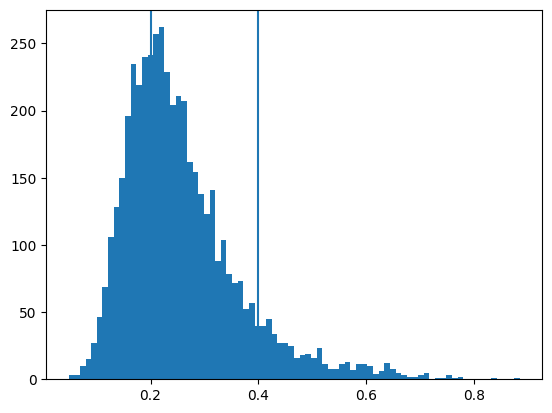

{'count': 4780.0, 'mean': 0.257, 'std': 0.108, 'min': 0.048, '25%': 0.183, '50%': 0.234, '75%': 0.304, 'max': 0.884}


In [ ]:
plt.hist(base, bins=80); plt.axvline(0.2); plt.axvline(0.4); plt.show()
print(pd.Series(base).describe().round(3).to_dict())

In [ ]:
tr = (Tm * Wv).sum(1)
for lab, m in [('DI_trend = 0', tr == 0), ('DI_trend > 0', tr > 0)]:
    s = pd.Series(base[m])
    print(f"{lab}: n={m.sum()} ({100*m.mean():.1f}%), "
          f"med={s.median():.3f}, p5={s.quantile(.05):.3f}, p95={s.quantile(.95):.3f}")

print('\nчисло осей со значимым трендом:')
print(pd.Series(Tm.sum(1).astype(int)).value_counts().sort_index().to_dict())

DI_trend = 0: n=3704 (77.5%), med=0.212, p5=0.123, p95=0.331
DI_trend > 0: n=1076 (22.5%), med=0.372, p5=0.244, p95=0.626

число осей со значимым трендом:
{0: 3704, 1: 677, 2: 213, 3: 126, 4: 51, 5: 9}


In [ ]:
TAU = 1.5
Ik = (A3 > TAU).sum(2) >= 3      # ось «сработала», если A>τ в ≥3 из 5 лет оценки
Ik = pd.DataFrame(Ik.astype(int), columns=IDX)

D = pd.DataFrame({
    'D1_стресс':    Ik.NDVI & Ik.LST,
    'D2_засуха':    Ik.NDVI & Ik.NDMI & Ik.LST,
    'D3_засоление': Ik.NDVI & Ik.SI,
    'D4_эрозия':    Ik.NDVI & Ik.TGSI,
    'D5_комплекс':  Ik.sum(1) >= 3,
})
print('доля пикселей с I^k=1:')
print((100*Ik.mean()).round(1).to_dict())
print('\nсигнатуры (перекрывающиеся):')
print((100*D.mean()).round(1).to_dict())
print('ни одной сигнатуры:', round(100*(~D.any(axis=1)).mean(), 1), '%')
print('\nсочетания сигнатур:')
print(D.astype(int).astype(str).agg(''.join, axis=1).value_counts().head(8).to_dict())

доля пикселей с I^k=1:
{'NDVI': 28.8, 'NDMI': 18.1, 'LST': 34.5, 'TGSI': 17.6, 'SI': 27.6}

сигнатуры (перекрывающиеся):
{'D1_стресс': 13.6, 'D2_засуха': 7.3, 'D3_засоление': 16.7, 'D4_эрозия': 7.7, 'D5_комплекс': 19.0}
ни одной сигнатуры: 75.4 %

сочетания сигнатур:
{'00000': 3606, '00100': 154, '11101': 147, '10101': 128, '00111': 123, '00101': 115, '11001': 108, '00001': 78}


In [ ]:
order = ['D5_комплекс', 'D2_засуха', 'D4_эрозия', 'D3_засоление', 'D1_стресс']
tp = pd.Series('норма', index=D.index)
for name in reversed(order):
    tp[D[name]] = name
print((100*tp.value_counts(normalize=True)).round(1).to_dict())

{'норма': 81.0, 'D5_комплекс': 19.0, 'D2_засуха': 0.0}


In [ ]:
D = D.astype(bool)
order = ['D5_комплекс','D2_засуха','D4_эрозия','D3_засоление','D1_стресс']
tp = pd.Series('норма', index=D.index)
for name in reversed(order):
    tp[D[name].values] = name
print((100*tp.value_counts(normalize=True)).round(1).to_dict())

{'норма': 75.4, 'D5_комплекс': 19.0, 'D3_засоление': 3.2, 'D1_стресс': 1.6, 'D4_эрозия': 0.8}


In [ ]:
order = ['D2_засуха','D4_эрозия','D3_засоление','D1_стресс']   # механизм
tp = pd.Series('норма', index=D.index)
for name in reversed(order):
    tp[D[name].values] = name

sev = Ik.sum(axis=1)                                            # тяжесть, 0–5
print('механизм:', (100*tp.value_counts(normalize=True)).round(1).to_dict())
print('охват осей:', (100*sev.value_counts(normalize=True).sort_index()).round(1).to_dict())
print('\nмеханизм × тяжесть:')
print(pd.crosstab(tp, sev >= 3, normalize='all').round(3)*100)

механизм: {'норма': 77.1, 'D3_засоление': 8.3, 'D2_засуха': 7.3, 'D4_эрозия': 5.7, 'D1_стресс': 1.6}
охват осей: {0: 37.0, 1: 27.5, 2: 16.5, 3: 11.4, 4: 6.1, 5: 1.5}

механизм × тяжесть:
col_0         False  True 
row_0                     
D1_стресс       1.6    0.0
D2_засуха       0.0    7.3
D3_засоление    3.2    5.1
D4_эрозия       0.8    4.9
норма          75.4    1.6


In [ ]:
gap = (~D.any(axis=1)) & (sev >= 3)
print('пикселей в разрыве:', gap.sum(), f'({100*gap.mean():.1f}%)')
print('оси:', (100*Ik[gap.values].mean()).round(1).to_dict())

пикселей в разрыве: 0 (0.0%)
оси: {'NDVI': nan, 'NDMI': nan, 'LST': nan, 'TGSI': nan, 'SI': nan}


In [ ]:
mech = ['D1_стресс','D2_засуха','D3_засоление','D4_эрозия']
gap = (~D[mech].any(axis=1)) & (sev >= 3)
print('пикселей в разрыве:', gap.sum(), f'({100*gap.mean():.1f}%)')
print('оси:', (100*Ik[gap.values].mean()).round(1).to_dict())

пикселей в разрыве: 78 (1.6%)
оси: {'NDVI': 0.0, 'NDMI': 35.9, 'LST': 97.4, 'TGSI': 76.9, 'SI': 94.9}


In [ ]:
A_st = ee.Image('projects/akmola/assets/A_stack_v2_2013_2024')
TAU, GAMMA, ALPHA = 1.5, 1.0, 0.6

A_coll = ee.ImageCollection([
    A_st.select([f'{k}_{y}' for k in IDX], IDX)
        .addBands(ee.Image.constant(y).toFloat().rename('t')) for y in years])

betas = ee.Image.cat([A_coll.select(['t',k]).reduce(ee.Reducer.sensSlope())
                      .select('slope').rename(k+'_beta') for k in IDX])
taus  = ee.Image.cat([A_coll.select(['t',k]).reduce(ee.Reducer.kendallsCorrelation(2))
                      .select(['tau'],[k+'_tau']) for k in IDX])
T = ee.Image.cat([betas.select(k+'_beta').gt(0)
                  .And(taus.select(k+'_tau').gte(0.4545)).rename('T_'+k) for k in IDX])

DI_trend = ee.Image.cat([T.select('T_'+k).multiply(W[k]) for k in IDX]) \
             .reduce(ee.Reducer.sum()).rename('DI_trend')

def phi(x): return ee.Image(1).divide(ee.Image(1).add(x.subtract(TAU).multiply(-GAMMA).exp()))
DI_thr = ee.ImageCollection([
    ee.Image.cat([phi(A_st.select(f'{k}_{y}')).multiply(W[k]) for k in IDX])
      .reduce(ee.Reducer.sum()) for y in EVAL_YEARS]).mean().rename('DI_thr')

DI = DI_thr.multiply(ALPHA).add(DI_trend.multiply(1-ALPHA)).rename('DI')

# пороговые индикаторы: A>τ в ≥3 из 5 лет оценки
I = ee.Image.cat([
    ee.ImageCollection([A_st.select(f'{k}_{y}').gt(TAU).rename(k) for y in EVAL_YEARS])
      .sum().gte(3).rename('I_'+k) for k in IDX])
sev = I.reduce(ee.Reducer.sum()).rename('severity')      # охват осей 0-5

# механизм: 1=D1, 2=D3, 3=D4, 4=D2 (приоритет от общего к специфичному)
mech = (ee.Image(0)
        .where(I.select('I_NDVI').And(I.select('I_LST')), 1)
        .where(I.select('I_NDVI').And(I.select('I_SI')), 2)
        .where(I.select('I_NDVI').And(I.select('I_TGSI')), 3)
        .where(I.select('I_NDVI').And(I.select('I_NDMI')).And(I.select('I_LST')), 4)
        .rename('mechanism'))

out = DI.addBands([DI_thr, DI_trend, sev, mech, T, betas, taus]).toFloat()
# task = ee.batch.Export.image.toAsset(
#     image=out, description='akmola_MITTCDA_v2',
#     assetId='projects/akmola/assets/MITTCDA_v2_2013_2024',
#     region=aoi, scale=30, maxPixels=1e13)
# task.start(); print(task.id)

WRVK7TZH5WLIWCADQDFVBHYU


In [ ]:
M = ee.Image('projects/akmola/assets/MITTCDA_v2_2013_2024')
print(M.bandNames().getInfo())

['DI', 'DI_thr', 'DI_trend', 'severity', 'mechanism', 'T_NDVI', 'T_NDMI', 'T_LST', 'T_TGSI', 'T_SI', 'NDVI_beta', 'NDMI_beta', 'LST_beta', 'TGSI_beta', 'SI_beta', 'NDVI_tau', 'NDMI_tau', 'LST_tau', 'TGSI_tau', 'SI_tau']


In [ ]:
names = {0:'норма', 1:'D1_стресс', 2:'D3_яркость', 3:'D4_эрозия', 4:'D2_засуха'}
g = ee.Image.pixelArea().divide(1e6).addBands(M.select('mechanism')).reduceRegion(
    reducer=ee.Reducer.sum().group(groupField=1, groupName='m'),
    geometry=aoi, scale=30, maxPixels=1e13, tileScale=16).getInfo()
tot = sum(x['sum'] for x in g['groups'])
for x in sorted(g['groups'], key=lambda z: -z['sum']):
    print(f"{names[int(x['m'])]}: {x['sum']:,.0f} км² ({100*x['sum']/tot:.1f}%)")
print(f"ИТОГО пашня: {tot:,.0f} км²")

норма: 111,508 км² (91.6%)
D2_засуха: 3,455 км² (2.8%)
D3_яркость: 3,053 км² (2.5%)
D4_эрозия: 2,578 км² (2.1%)
D1_стресс: 1,143 км² (0.9%)
ИТОГО пашня: 121,737 км²


In [ ]:
g2 = ee.Image.pixelArea().divide(1e6).addBands(M.select('severity')).reduceRegion(
    reducer=ee.Reducer.sum().group(groupField=1, groupName='s'),
    geometry=aoi, scale=30, maxPixels=1e13, tileScale=16).getInfo()
for x in sorted(g2['groups'], key=lambda z: z['s']):
    print(f"осей затронуто {int(x['s'])}: {x['sum']:,.0f} км²")

осей затронуто 0: 24,400 км²
осей затронуто 1: 16,352 км²
осей затронуто 2: 8,642 км²
осей затронуто 3: 5,212 км²
осей затронуто 4: 2,525 км²
осей затронуто 5: 532 км²


In [ ]:
mech_ok = M.select('mechanism').updateMask(M.select('severity').mask())
g = ee.Image.pixelArea().divide(1e6).addBands(mech_ok).reduceRegion(
    reducer=ee.Reducer.sum().group(groupField=1, groupName='m'),
    geometry=aoi, scale=30, maxPixels=1e13, tileScale=16).getInfo()
tot = sum(x['sum'] for x in g['groups'])
for x in sorted(g['groups'], key=lambda z: -z['sum']):
    print(f"{names[int(x['m'])]}: {x['sum']:,.0f} км² ({100*x['sum']/tot:.1f}%)")

норма: 47,434 км² (82.3%)
D2_засуха: 3,455 км² (6.0%)
D3_яркость: 3,053 км² (5.3%)
D4_эрозия: 2,578 км² (4.5%)
D1_стресс: 1,143 км² (2.0%)


In [ ]:
M = ee.Image('projects/akmola/assets/MITTCDA_v2_2013_2024')
px = ee.Image.pixelArea().divide(1e6)

# доли T^k и площади
for k in IDX:
    a = px.updateMask(M.select('T_'+k)).reduceRegion(
        ee.Reducer.sum(), aoi, 30, maxPixels=1e13, tileScale=16).getInfo()['area']
    print(f"T_{k}: {a:,.0f} км²")

# пересечение: механизм сработал И хотя бы одна ось с трендом
nT = M.select(['T_'+k for k in IDX]).reduce(ee.Reducer.sum()).rename('nT')
both = M.select('mechanism').gt(0).And(nT.gt(0))
for lab, im in [('тренд ≥1 ось', nT.gt(0)), ('тренд ≥2 оси', nT.gte(2)),
                ('механизм + тренд', both)]:
    a = px.updateMask(im).reduceRegion(
        ee.Reducer.sum(), aoi, 30, maxPixels=1e13, tileScale=16).getInfo()['area']
    print(f"{lab}: {a:,.0f} км² ({100*a/57663:.1f}%)")

# распределение DI
print(M.select(['DI','DI_thr','DI_trend']).reduceRegion(
    ee.Reducer.percentile([5,25,50,75,95]).combine(ee.Reducer.max(), sharedInputs=True),
    aoi, 30, maxPixels=1e13, tileScale=16).getInfo())

T_NDVI: 3,953 км²
T_NDMI: 3,017 км²
T_LST: 2,061 км²
T_TGSI: 3,269 км²
T_SI: 5,021 км²
тренд ≥1 ось: 10,540 км² (18.3%)
тренд ≥2 оси: 4,232 км² (7.3%)
механизм + тренд: 3,747 км² (6.5%)
{'DI_max': 0.9943472146987915, 'DI_p25': 0.1699270870484097, 'DI_p5': 0.11917876685241788, 'DI_p50': 0.21678967725729006, 'DI_p75': 0.2831872346656026, 'DI_p95': 0.45507156088973894, 'DI_thr_max': 0.9985272288322449, 'DI_thr_p25': 0.2793012291228046, 'DI_thr_p5': 0.19338154478564937, 'DI_thr_p50': 0.34960767404114773, 'DI_thr_p75': 0.43553900870542533, 'DI_thr_p95': 0.5683474237506918, 'DI_trend_max': 1, 'DI_trend_p25': 0, 'DI_trend_p5': 0, 'DI_trend_p50': 0, 'DI_trend_p75': 0, 'DI_trend_p95': 0.39399999380111683}
